#  Analysis of the Cosmos 2612 – ICEYE-X36 RPO from Public GP Data

**Objects:** ICEYE-X36 (NORAD 59103) and Cosmos 2612 (NORAD 68762)
**Data:** Space-Track general perturbations (GP) element history, 1 April – 27 October 2026, propagated with SGP4
**Analysis window:** 1–27 October 2026
**Author:** Brayan Nicolas Buitrago Montenegro

This notebook contains the complete analysis supporting the article *"Analysis of the Cosmos 2612 – ICEYE-X36 RPO from Public GP Data"*. All figures and tables in the article are produced here.

**Research question:** can the close approach observed in October 2026 be explained by natural orbital evolution (chance encounter or natural co-orbital drift), or did it require manoeuvres, and by which object?

### Contents
0. Hypotheses and decision rules
1. Configuration
2. Data
3. Mean orbital elements
4. Orbital history of each object
5. Manoeuvre detection
6. Empirical SGP4 prediction error
7. Relative orbital geometry
8. Relative distance and closest approach
9. Relative motion in the RIC frame
10. Test R1: ballistic counterfactual
11. Summary figure and verdict with the pre-specified rules
12. Revised decision rules
13. Bias assessment: parameter sensitivity and negative controls
14. Limitations

**Requirements:** Python ≥ 3.11, `numpy`, `pandas`, `scipy`, `matplotlib`, `sgp4` (and `requests` for `src/download_data.py`).

## 0. Hypotheses and decision rules

To avoid confirmation bias, hypotheses, methods and thresholds are defined here and applied **identically to both objects**. The verdict is generated automatically from these rules (Section 11).

**Hypotheses**

- **H0 (natural evolution):** the relative trajectory around the time of closest approach (TCA) is the ballistic (manoeuvre-free) continuation of the prior orbital state of both objects. This covers both a chance encounter and natural co-orbital drift.
- **H1 (induced approach):** the observed relative trajectory cannot be obtained by ballistic propagation of the prior state, and the discrepancy coincides with detected manoeuvres.

**Tests**

| Test | What it measures | Rule |
|---|---|---|
| R1 – Need for manoeuvres (ballistic counterfactual) | The TLEs available $L$ days before TCA are propagated without manoeuvres and the predicted relative position is compared with the observed one at TCA. | H0 is rejected for a given $L$ if the discrepancy exceeds $K_{err}$ times the 95th-percentile SGP4 prediction error, measured empirically for the same objects over a reference period. |
| R2 – Attribution | Does the manoeuvre detector (Section 5), applied identically to both objects, find any event between the cut-off that rejects H0 and TCA? For which object? | Yes / No |
| R3 – Direction of the effect | For cut-offs rejecting H0, is the observed minimum distance smaller than the ballistic one beyond the error? Manoeuvres unrelated to the encounter could equally move the objects apart. | $d_{min,obs} + K_{err}\,\varepsilon_{95} < d_{min,bal}$ |

**Verdict**
- R1 not met → *H0 not rejected* (approach consistent with natural evolution).
- R1, R2 and R3 met → *H0 rejected: manoeuvre-induced approach*.
- R1 and R2 met, R3 not met → manoeuvres occurred but do not explain the approach.
- R1 met, R2 not met → discrepancy without an identified manoeuvre: *inconclusive*.

Descriptive metrics (minimum distance, relative velocity, time in proximity, coplanarity, manoeuvre frequency) are reported but **do not decide the outcome on their own**: a low relative velocity, for instance, also occurs in natural co-orbital drift. Kinematics cannot establish *intent*; they can only establish that the approach *required* manoeuvres.

## 1. Configuration

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from scipy.signal import find_peaks
from sgp4.api import Satrec

plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True, "savefig.dpi": 300})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

MU = 398600.4418  # km^3/s^2

NORAD_A, NORAD_B = 59103, 68762
NORAD_IDS = [NORAD_A, NORAD_B]
NAME = {NORAD_A: "ICEYE-X36", NORAD_B: "Cosmos 2612"}
LABEL = {n: f"{NAME[n]} ({n})" for n in NORAD_IDS}
COLOR = {NORAD_A: "tab:blue", NORAD_B: "tab:orange"}

# Time intervals
DATA_START = pd.Timestamp("2026-04-01", tz="UTC")
DATA_END = pd.Timestamp("2026-10-28", tz="UTC")
REFERENCE_END = pd.Timestamp("2026-09-01", tz="UTC")   # reference period: TLEs before this date
CONTEXT_START = pd.Timestamp("2026-09-01", tz="UTC")   # test period: prior context + analysis window
WINDOW_START = pd.Timestamp("2026-10-01 00:00", tz="UTC")
WINDOW_END = pd.Timestamp("2026-10-27 23:59", tz="UTC")

# Decision parameters
Z_THRESHOLD = 5.0          # robust |z| flagging a change between consecutive TLEs
EVENT_GAP_DAYS = 1.5       # flagged pairs closer than this form a single event
ALPHA = 0.01               # overall significance level
K_ERR = 3.0                # factor on the SGP4 p95 error used to reject H0 in R1
ERROR_LEADS_DAYS = [0.25, 0.5, 1, 2, 3, 5, 7, 10, 14]
CF_LEADS_DAYS = [0.5, 1, 2, 3, 5, 7, 10]
THRESHOLDS_KM = [1.0, 5.0, 25.0]
STEP_S = 60

TLE_FILE = os.path.join("data", "tle_gp_history_59103_68762.csv")
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)


def save(fig, name):
    fig.savefig(os.path.join(OUTPUT_DIR, name), bbox_inches="tight")

## 2. Data

GP element history (TLE format) for both objects, retrieved from Space-Track (`gp_history` class) for epochs between 1 April and 28 October 2026.

> **Data availability.** Due to Space-Track.org User Agreement restrictions regarding data redistribution, the raw TLE file is not included in the repository. Register a free account at [Space-Track.org](https://www.space-track.org), set `SPACETRACK_USER` and `SPACETRACK_PASSWORD` as environment variables and run `python src/download_data.py` from the repository root. The script writes `data/tle_gp_history_59103_68762.csv` (1408 records in the original download).

In [2]:
if not os.path.exists(TLE_FILE):
    raise FileNotFoundError(
        f"{TLE_FILE} not found. Download it first with `python src/download_data.py` "
        "(requires a free Space-Track.org account; see the README)."
    )
df_raw = pd.read_csv(TLE_FILE)
print(f"Records: {len(df_raw)}")

Records: 1408


## 3. Mean orbital elements

The SGP4 mean elements are obtained for each TLE. Semi-major axis and perigee/apogee altitudes:

$$a = \left(\frac{\mu}{n^2}\right)^{1/3},\qquad h_p = a(1-e) - R_\oplus,\qquad h_a = a(1+e) - R_\oplus$$

When several element sets share the same epoch, the most recently created one is kept.

In [3]:
col_l1 = next(c for c in ["TLE_LINE1", "TLE_LINE_1", "LINE1"] if c in df_raw.columns)
col_l2 = next(c for c in ["TLE_LINE2", "TLE_LINE_2", "LINE2"] if c in df_raw.columns)

df_tle = pd.DataFrame({
    "norad": pd.to_numeric(df_raw["NORAD_CAT_ID"], errors="coerce"),
    "epoch": pd.to_datetime(df_raw["EPOCH"], utc=True, errors="coerce"),
    "created": pd.to_datetime(df_raw["CREATION_DATE"], utc=True, errors="coerce")
    if "CREATION_DATE" in df_raw.columns else pd.NaT,
    "line1": df_raw[col_l1].astype(str).str.strip(),
    "line2": df_raw[col_l2].astype(str).str.strip(),
}).dropna(subset=["norad", "epoch"])
df_tle["norad"] = df_tle["norad"].astype(int)

n_before = len(df_tle)
df_tle = (df_tle.sort_values(["norad", "epoch", "created"])
          .drop_duplicates(["norad", "epoch"], keep="last"))
df_tle = df_tle[(df_tle["epoch"] >= DATA_START) & (df_tle["epoch"] < DATA_END)]
print(f"Duplicate epochs removed: {n_before - len(df_tle)}")

df_tle["sat"] = [Satrec.twoline2rv(l1, l2) for l1, l2 in zip(df_tle["line1"], df_tle["line2"])]
R_E = df_tle["sat"].iloc[0].radiusearthkm
df_tle["a_km"] = [s.a * s.radiusearthkm for s in df_tle["sat"]]
df_tle["mean_alt_km"] = df_tle["a_km"] - R_E
df_tle["hp_km"] = [s.altp * s.radiusearthkm for s in df_tle["sat"]]
df_tle["ha_km"] = [s.alta * s.radiusearthkm for s in df_tle["sat"]]
df_tle["ecc"] = [s.ecco for s in df_tle["sat"]]
df_tle["inc_deg"] = [np.degrees(s.inclo) for s in df_tle["sat"]]
df_tle["raan_deg"] = [np.degrees(s.nodeo) for s in df_tle["sat"]]
df_tle["n_rev_day"] = [s.no_kozai * 1440 / (2 * np.pi) for s in df_tle["sat"]]
df_tle["bstar"] = [s.bstar for s in df_tle["sat"]]

tles = {n: df_tle[df_tle["norad"] == n].sort_values("epoch").reset_index(drop=True) for n in NORAD_IDS}

summary = df_tle.groupby("norad").agg(
    n_tle=("epoch", "size"), first_epoch=("epoch", "min"), last_epoch=("epoch", "max"))
summary.insert(0, "object", [NAME[n] for n in summary.index])
summary["tle_per_day"] = summary["n_tle"] / ((summary["last_epoch"] - summary["first_epoch"]).dt.total_seconds() / 86400)
display(summary)

Duplicate epochs removed: 54


,object,n_tle,first_epoch,last_epoch,tle_per_day
norad,,,,,
59103,ICEYE-X36,758,2026-04-01 03:21:05.817888+00:00,2026-10-27 06:39:21.970368+00:00,3.6244
68762,Cosmos 2612,596,2026-04-18 05:22:26.233536+00:00,2026-10-27 06:40:26.566464+00:00,3.1033


### Propagation functions

`ephemeris` propagates in vectorised form (`sgp4_array`) in the TEME frame. The element set used at each instant is selected in one of three ways:

- `previous`: the most recent TLE with epoch ≤ t (causal). Main mode, used throughout.
- `nearest`: the TLE whose epoch is closest to t. Used in Section 8 to identify artefacts caused by TLE switching.
- `fixed_row`: the same TLE for every instant, i.e. a ballistic propagation. Used in the counterfactual tests.

In [4]:
def _ns(times):
    t = pd.DatetimeIndex(times)
    if t.tz is None:
        t = t.tz_localize("UTC")
    return t.tz_convert("UTC").tz_localize(None).as_unit("ns").asi8


def to_jd(times):
    days = _ns(times) / 86400e9
    base = np.floor(days)
    return 2440587.5 + base, days - base


EPOCHS_NS = {n: _ns(tles[n]["epoch"]) for n in NORAD_IDS}


def ephemeris(norad, times, mode="previous", fixed_row=None):
    times = pd.DatetimeIndex(times)
    t_ns = _ns(times)
    ep = EPOCHS_NS[norad]
    if fixed_row is not None:
        idx = np.full(len(t_ns), int(fixed_row))
    elif mode == "previous":
        idx = np.searchsorted(ep, t_ns, side="right") - 1
    elif mode == "nearest":
        j = np.clip(np.searchsorted(ep, t_ns), 1, len(ep) - 1)
        idx = np.where(np.abs(t_ns - ep[j - 1]) <= np.abs(ep[j] - t_ns), j - 1, j)
    else:
        raise ValueError(mode)

    jd, fr = to_jd(times)
    r = np.full((len(t_ns), 3), np.nan)
    v = np.full((len(t_ns), 3), np.nan)
    for k in np.unique(idx[idx >= 0]):
        m = idx == k
        e, rr, vv = tles[norad].at[k, "sat"].sgp4_array(jd[m], fr[m])
        rr, vv = np.asarray(rr), np.asarray(vv)
        rr[e != 0] = np.nan
        vv[e != 0] = np.nan
        r[m], v[m] = rr, vv
    age_h = np.where(idx >= 0, (t_ns - ep[np.maximum(idx, 0)]) / 3.6e12, np.nan)
    return r, v, idx, age_h


def local_rel_velocity(rA, vA, rB, vB):
    # Velocity of B relative to A in A's local (RIC) frame, rotating with ω = h/r²
    h = np.cross(rA, vA)
    w = h / (np.linalg.norm(rA, axis=1) ** 2)[:, None]
    return np.linalg.norm((vB - vA) - np.cross(w, rB - rA), axis=1)


def propagate(sat, instant):
    jd, fr = to_jd([instant])
    e, r, v = sat.sgp4(jd[0], fr[0])
    return (np.array(r), np.array(v)) if e == 0 else (np.full(3, np.nan), np.full(3, np.nan))

## 4. Orbital history of each object

Mean SGP4 elements of each object over the full data span and from 1 September onwards. The shaded band marks the analysis window.

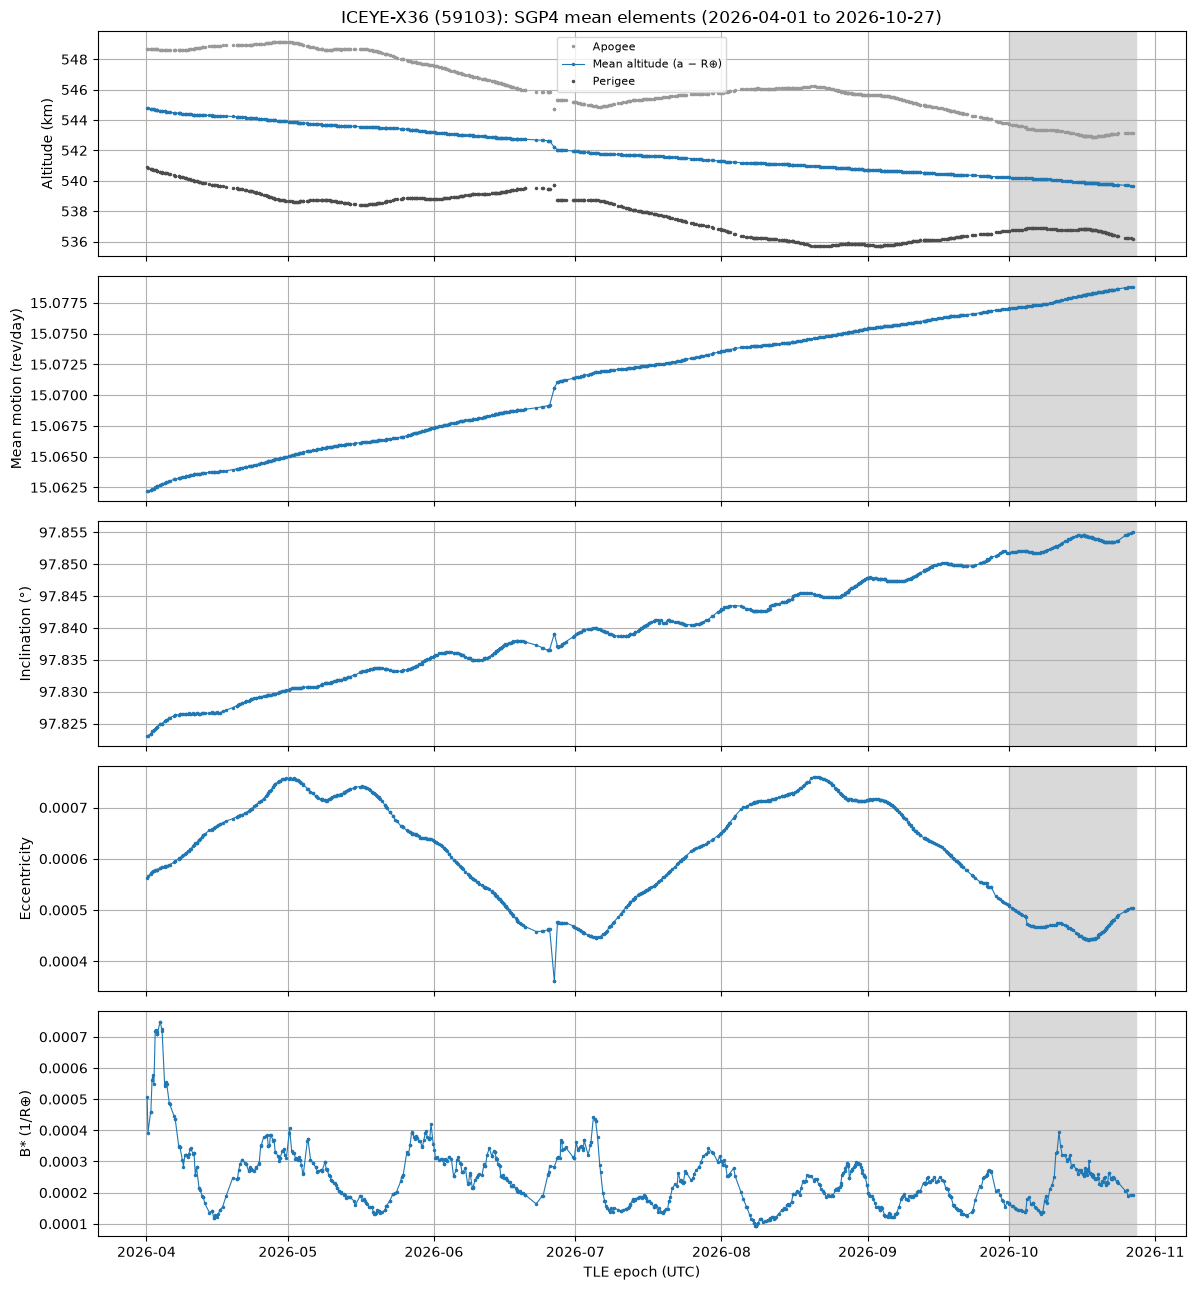

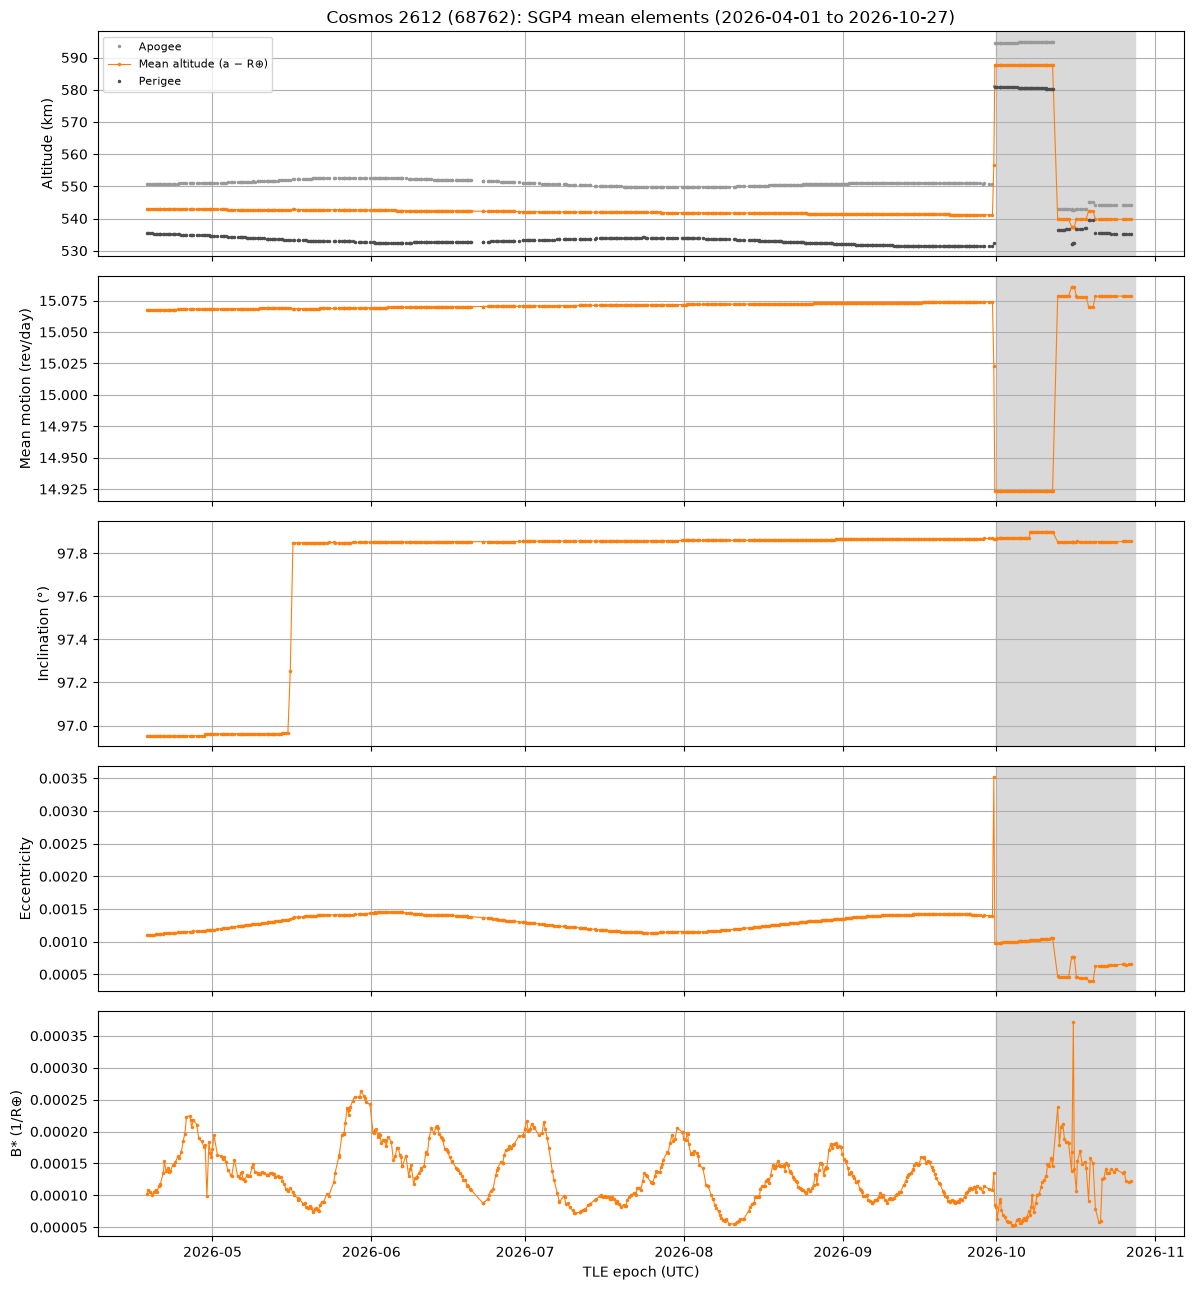

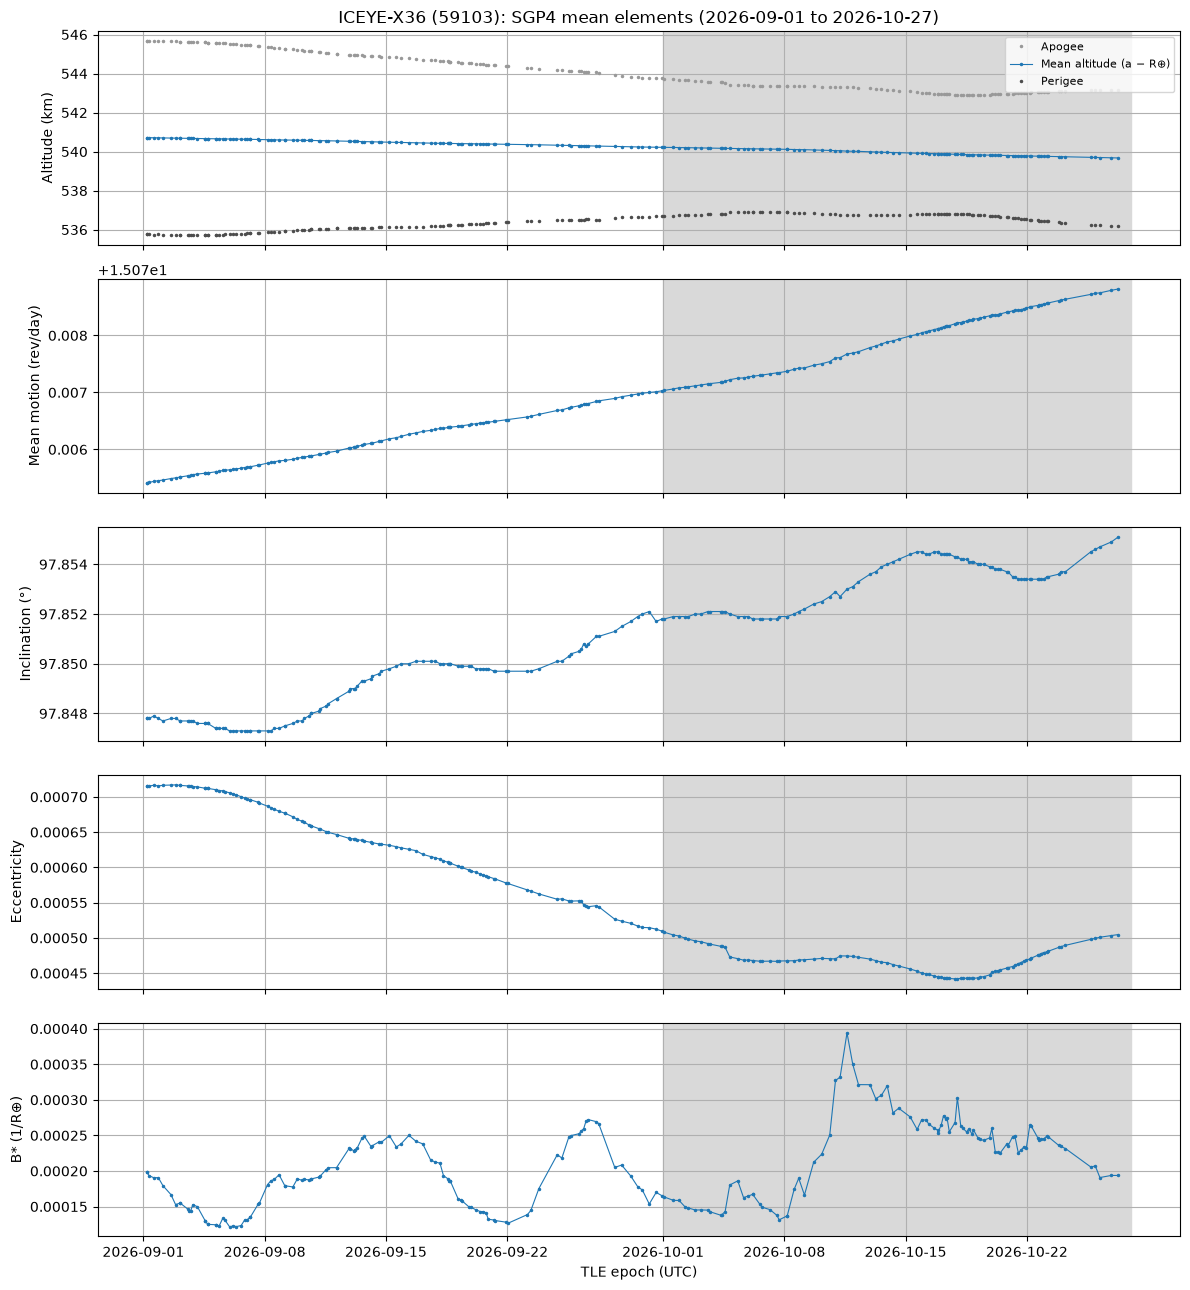

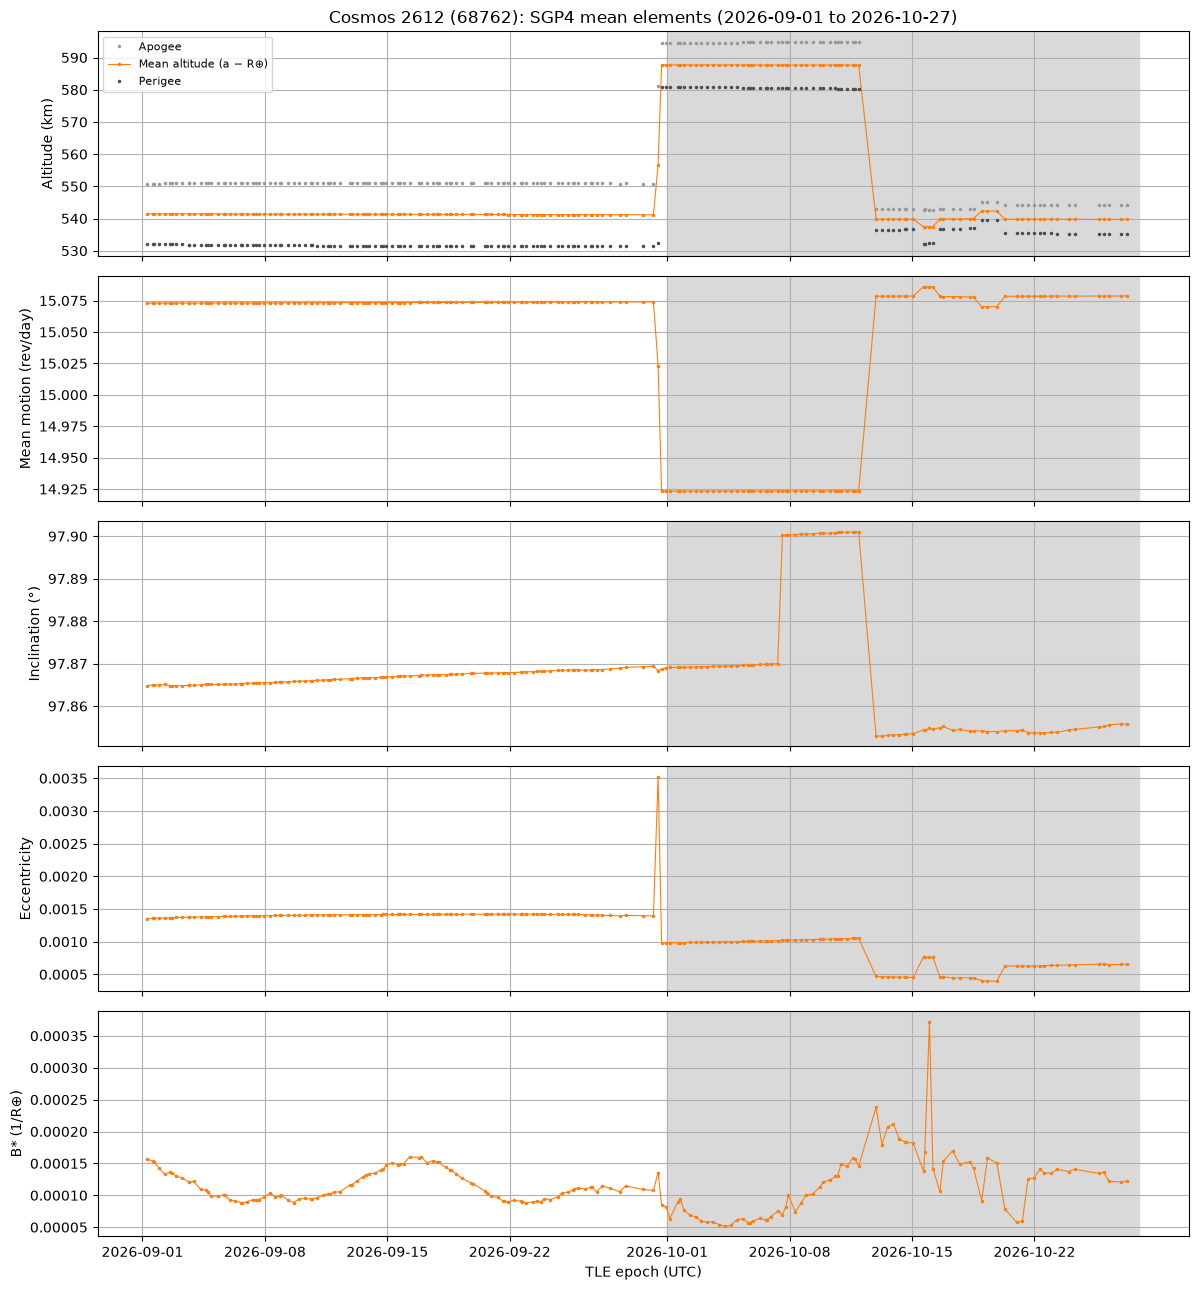

In [5]:
def plot_history(norad, t0, t1, suffix):
    sub = tles[norad]
    sub = sub[(sub["epoch"] >= t0) & (sub["epoch"] <= t1)]
    fig, ax = plt.subplots(5, 1, sharex=True, figsize=(12, 13))
    ax[0].plot(sub["epoch"], sub["ha_km"], ".", ms=3, color="0.6", label="Apogee")
    ax[0].plot(sub["epoch"], sub["mean_alt_km"], ".-", ms=3, lw=0.8, color=COLOR[norad], label="Mean altitude (a − R⊕)")
    ax[0].plot(sub["epoch"], sub["hp_km"], ".", ms=3, color="0.3", label="Perigee")
    ax[0].set_ylabel("Altitude (km)")
    ax[0].legend(loc="best", fontsize=8)
    ax[1].plot(sub["epoch"], sub["n_rev_day"], ".-", ms=3, lw=0.8, color=COLOR[norad])
    ax[1].set_ylabel("Mean motion (rev/day)")
    ax[2].plot(sub["epoch"], sub["inc_deg"], ".-", ms=3, lw=0.8, color=COLOR[norad])
    ax[2].set_ylabel("Inclination (°)")
    ax[3].plot(sub["epoch"], sub["ecc"], ".-", ms=3, lw=0.8, color=COLOR[norad])
    ax[3].set_ylabel("Eccentricity")
    ax[4].plot(sub["epoch"], sub["bstar"], ".-", ms=3, lw=0.8, color=COLOR[norad])
    ax[4].set_ylabel("B* (1/R⊕)")
    ax[4].set_xlabel("TLE epoch (UTC)")
    for a in ax:
        a.axvspan(WINDOW_START, WINDOW_END, color="0.85", zorder=0)
    ax[0].set_title(f"{LABEL[norad]}: SGP4 mean elements ({t0:%Y-%m-%d} to {t1:%Y-%m-%d})")
    fig.tight_layout()
    save(fig, f"history_{norad}_{suffix}.png")
    plt.show()


t_first = df_tle["epoch"].min()
for n in NORAD_IDS:
    plot_history(n, t_first, WINDOW_END, "full")
for n in NORAD_IDS:
    plot_history(n, CONTEXT_START, WINDOW_END, "context")

## 5. Manoeuvre detection

The same algorithm is applied to both objects. For each pair of consecutive TLEs $(k-1, k)$:

1. $\Delta a_k = a_k - a_{k-1}$ and $\Delta i_k = i_k - i_{k-1}$.
2. The propagation residual $\rho_k = \lVert \mathbf r_{k-1}(t_k) - \mathbf r_k(t_k) \rVert$, normalised by the time between epochs (km/day, minimum interval 0.25 days).

Each series is converted into a robust score using **only the reference period** (before `REFERENCE_END`):

$$z = \frac{x - \operatorname{median}(x_{ref})}{1.4826\,\operatorname{MAD}(x_{ref})}$$

A pair is flagged if $|z_{\Delta a}|$, $|z_{\Delta i}|$ or $z_\rho$ exceeds `Z_THRESHOLD`. Flagged pairs less than `EVENT_GAP_DAYS` apart are grouped into one event. The minimum $\Delta v$ of each event is estimated with an impulsive, near-circular approximation:

$$\Delta v_a \approx \frac{v}{2a}\,|\Delta a|,\qquad \Delta v_i = 2v\sin\frac{|\Delta i|}{2},\qquad v=\sqrt{\mu/a}$$

The two components are perpendicular (along-track and normal to the orbital plane), so they are combined in quadrature, $\Delta v = \sqrt{\Delta v_a^2 + \Delta v_i^2}$, as in a single burn that changes both. These are **lower bounds**: several manoeuvres between two TLEs appear as one. Two values are given: **net**, from the first to the last TLE of the event, and **gross**, the sum of $\Delta v$ over consecutive pairs (each pair combined in quadrature), which prevents burns of opposite sign from cancelling out.

In [6]:
def robust_z(x, x_ref):
    med = np.nanmedian(x_ref)
    mad = 1.4826 * np.nanmedian(np.abs(x_ref - med))
    return (x - med) / max(mad, 1e-12)


def tle_diagnostics(norad):
    sub = tles[norad]
    rows = []
    for k in range(1, len(sub)):
        p, c = sub.iloc[k - 1], sub.iloc[k]
        rp, _ = propagate(p["sat"], c["epoch"])
        rc, _ = propagate(c["sat"], c["epoch"])
        dt_d = (c["epoch"] - p["epoch"]).total_seconds() / 86400
        rows.append({
            "norad": norad, "prev_epoch": p["epoch"], "epoch": c["epoch"], "dt_days": dt_d,
            "pos_residual_km": np.linalg.norm(rp - rc),
            "da_km": c["a_km"] - p["a_km"], "di_deg": c["inc_deg"] - p["inc_deg"],
        })
    d = pd.DataFrame(rows)
    d["residual_rate_km_day"] = d["pos_residual_km"] / d["dt_days"].clip(lower=0.25)
    ref = d[d["epoch"] < REFERENCE_END]
    d["z_a"] = robust_z(d["da_km"], ref["da_km"])
    d["z_i"] = robust_z(d["di_deg"], ref["di_deg"])
    d["z_res"] = robust_z(d["residual_rate_km_day"], ref["residual_rate_km_day"])
    d["flagged"] = (d["z_a"].abs() > Z_THRESHOLD) | (d["z_i"].abs() > Z_THRESHOLD) | (d["z_res"] > Z_THRESHOLD)
    return d


def group_events(d, norad):
    sub = tles[norad].set_index("epoch")
    flagged = d[d["flagged"]]
    groups, current = [], []
    for _, row in flagged.iterrows():
        if current and (row["prev_epoch"] - current[-1]["epoch"]).total_seconds() / 86400 > EVENT_GAP_DAYS:
            groups.append(current)
            current = []
        current.append(row)
    if current:
        groups.append(current)

    rows = []
    for g in groups:
        g = pd.DataFrame(g)
        start, end = g["prev_epoch"].min(), g["epoch"].max()
        a0, a1 = sub.at[start, "a_km"], sub.at[end, "a_km"]
        i0, i1 = sub.at[start, "inc_deg"], sub.at[end, "inc_deg"]
        v = np.sqrt(MU / a0)
        dv_a = v / (2 * a0) * abs(a1 - a0) * 1000
        dv_i = 2 * v * np.sin(np.radians(abs(i1 - i0)) / 2) * 1000
        dv_gross = np.hypot(v / (2 * a0) * g["da_km"].abs() * 1000,
                            2 * v * np.sin(np.radians(g["di_deg"].abs()) / 2) * 1000).sum()
        rows.append({
            "norad": norad, "start": start, "end": end, "n_pairs": len(g),
            "da_net_km": a1 - a0, "di_net_deg": i1 - i0,
            "dv_a_m_s": dv_a, "dv_i_m_s": dv_i, "dv_net_m_s": np.hypot(dv_a, dv_i), "dv_gross_m_s": dv_gross,
            "z_max": np.nanmax(np.abs(g[["z_a", "z_i", "z_res"]].values)),
        })
    return pd.DataFrame(rows, columns=["norad", "start", "end", "n_pairs", "da_net_km", "di_net_deg",
                                       "dv_a_m_s", "dv_i_m_s", "dv_net_m_s", "dv_gross_m_s", "z_max"])


diag = {n: tle_diagnostics(n) for n in NORAD_IDS}
events = {n: group_events(diag[n], n) for n in NORAD_IDS}
df_events = pd.concat(events.values(), ignore_index=True)
df_events.to_csv(os.path.join(OUTPUT_DIR, "manoeuvre_events.csv"), index=False)

for n in NORAD_IDS:
    print(f"\n=== {LABEL[n]}: detected events (full history) ===")
    display(events[n])


=== ICEYE-X36 (59103): detected events (full history) ===


,norad,start,end,n_pairs,da_net_km,di_net_deg,dv_a_m_s,dv_i_m_s,dv_net_m_s,dv_gross_m_s,z_max
0,59103,2026-04-02 14:25:40.768320+00:00,2026-04-03 20:43:14.461248+00:00,2,-0.0905,0.0009,0.0496,0.1192,0.1291,0.0872,8.3198
1,59103,2026-04-05 22:08:40.447968+00:00,2026-04-06 20:27:52.981920+00:00,1,-0.0377,0.0003,0.0207,0.0397,0.0448,0.0448,7.4259
2,59103,2026-04-11 02:29:52.296864+00:00,2026-04-11 08:52:29.481024+00:00,1,0.0006,0.0000,0.0003,0.0000,0.0003,0.0003,6.4167
3,59103,2026-04-17 21:06:33.900192+00:00,2026-04-20 14:28:18.970176+00:00,2,-0.0552,0.0009,0.0303,0.1192,0.1230,0.0695,5.4645
4,59103,2026-04-30 16:46:56.073504+00:00,2026-05-01 07:07:44.541120+00:00,1,-0.0276,0.0000,0.0151,0.0000,0.0151,0.0151,5.5783
5,59103,2026-05-04 06:51:44.000352+00:00,2026-05-05 03:35:05.625888+00:00,1,-0.0324,0.0000,0.0178,0.0000,0.0178,0.0178,6.2300
6,59103,2026-05-31 02:49:23.983680+00:00,2026-05-31 09:11:55.398912+00:00,1,-0.0154,0.0001,0.0085,0.0132,0.0157,0.0157,5.4010
7,59103,2026-06-20 08:55:14.856672+00:00,2026-06-22 16:41:58.292448+00:00,1,-0.0358,-0.0005,0.0196,0.0662,0.0691,0.0691,6.9909
8,59103,2026-06-25 13:13:37.286400+00:00,2026-06-27 05:03:52.407072+00:00,2,-0.5769,0.0005,0.3163,0.0662,0.3231,0.6839,217.3862
9,59103,2026-06-28 22:29:38.706720+00:00,2026-06-30 12:44:10.954176+00:00,1,-0.0402,0.0008,0.0220,0.1060,0.1082,0.1082,7.9871



=== Cosmos 2612 (68762): detected events (full history) ===


,norad,start,end,n_pairs,da_net_km,di_net_deg,dv_a_m_s,dv_i_m_s,dv_net_m_s,dv_gross_m_s,z_max
0,68762,2026-04-19 13:15:01.888416+00:00,2026-04-21 22:37:41.382912+00:00,4,-0.0258,0.0007,0.0142,0.0927,0.0938,0.0550,18.9676
1,68762,2026-04-24 22:20:58.653024+00:00,2026-04-25 14:17:15.457056+00:00,2,-0.0146,0.0000,0.0080,0.0000,0.0080,0.0080,8.8951
2,68762,2026-04-29 07:32:22.393248+00:00,2026-04-29 13:54:52.717248+00:00,1,-0.0055,0.0081,0.0030,1.0729,1.0729,1.0729,54.6338
3,68762,2026-05-15 17:11:32.011008+00:00,2026-05-16 17:05:52.153152+00:00,2,0.1429,0.8865,0.0784,117.4200,117.4201,117.4208,"4,025.3609"
4,68762,2026-05-28 17:33:23.645088+00:00,2026-05-31 17:16:14.659104+00:00,3,-0.0737,0.0015,0.0404,0.1987,0.2028,0.1619,6.9846
5,68762,2026-06-20 10:33:53.375904+00:00,2026-06-22 16:44:41.724096+00:00,1,-0.0189,0.0000,0.0104,0.0000,0.0104,0.0104,6.4543
6,68762,2026-07-21 07:31:42.761568+00:00,2026-07-21 15:29:44.174688+00:00,1,-0.0046,0.0001,0.0025,0.0132,0.0135,0.0135,5.3016
7,68762,2026-07-30 16:11:51.038592+00:00,2026-07-31 16:05:53.137824+00:00,1,-0.0162,0.0004,0.0089,0.0530,0.0537,0.0537,5.3279
8,68762,2026-08-28 21:15:35.966880+00:00,2026-08-29 06:49:10.671456+00:00,1,-0.0026,-0.0001,0.0014,0.0132,0.0133,0.0133,6.4021
9,68762,2026-09-13 22:49:23.661120+00:00,2026-09-15 06:41:14.467488+00:00,2,-0.0171,0.0002,0.0094,0.0265,0.0281,0.0036,6.2667


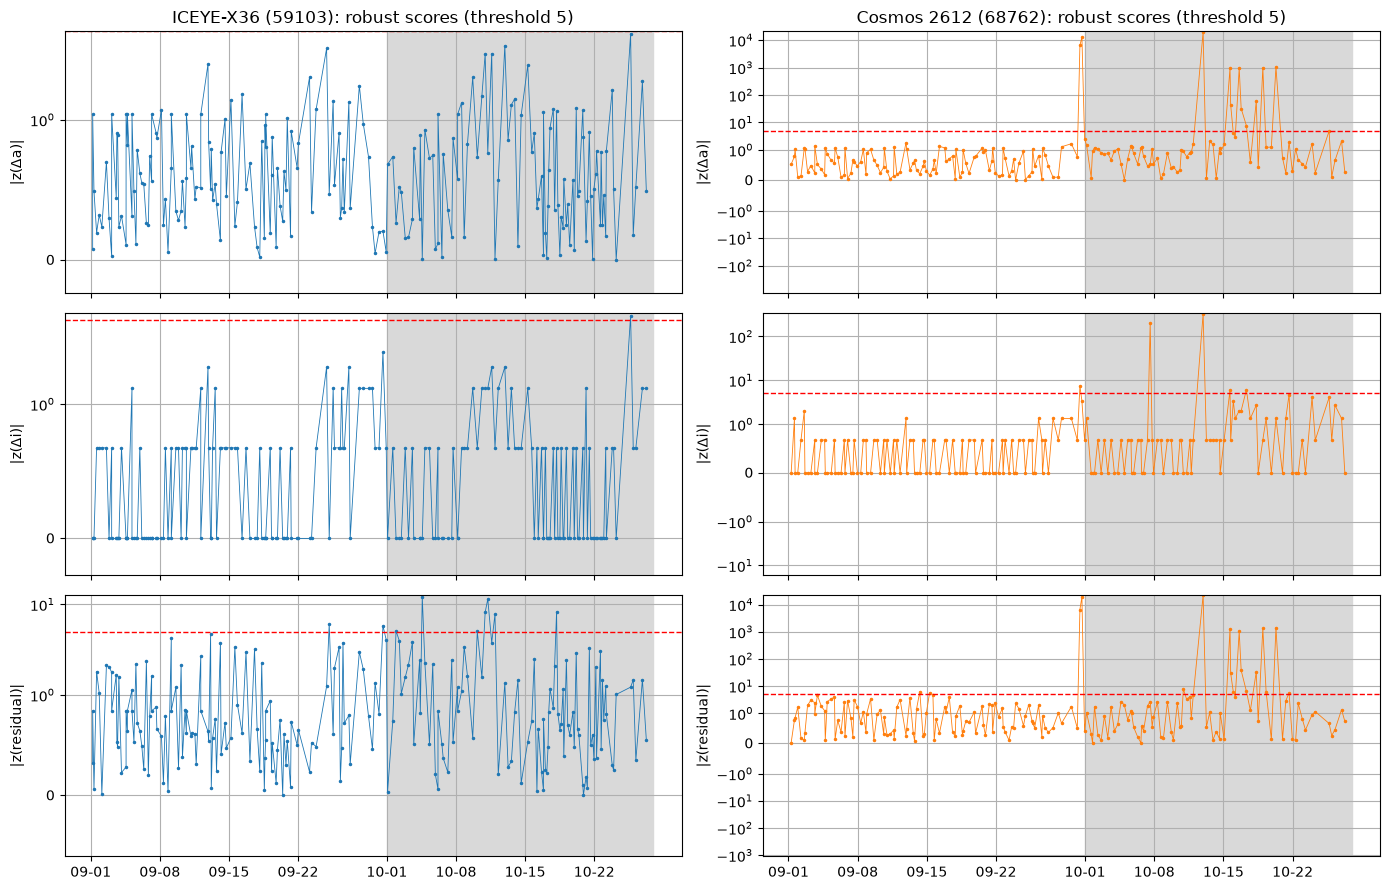

In [7]:
fig, ax = plt.subplots(3, 2, sharex="col", figsize=(14, 9))
for j, n in enumerate(NORAD_IDS):
    d = diag[n]
    d = d[d["epoch"] >= CONTEXT_START]
    for i, (col, name) in enumerate([("z_a", "z(Δa)"), ("z_i", "z(Δi)"), ("z_res", "z(residual)")]):
        a = ax[i, j]
        a.plot(d["epoch"], d[col].abs(), ".-", ms=3, lw=0.6, color=COLOR[n])
        a.axhline(Z_THRESHOLD, color="red", ls="--", lw=1)
        a.set_yscale("symlog", linthresh=1)
        a.set_ylabel(f"|{name}|")
        a.axvspan(WINDOW_START, WINDOW_END, color="0.85", zorder=0)
    ax[0, j].set_title(f"{LABEL[n]}: robust scores (threshold {Z_THRESHOLD:g})")
    ax[2, j].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
fig.tight_layout()
save(fig, "manoeuvre_detection.png")
plt.show()

### Manoeuvre frequency (descriptive)

The number of events $k$ in the test period (context + analysis window) is compared with the rate observed in the reference period, assuming a Poisson distribution with $\lambda = \hat r_{ref}\,T_{test}$ and $\hat r_{ref} = (k_{ref}+1)/T_{ref}$ (a conservative estimate that is never zero). Because the detector is applied identically in both periods, the reference rate also includes its false alarms.

This result **does not enter the verdict**: an object that manoeuvres frequently would show no excess and could still have induced the approach.

In [8]:
rows = []
T_test = (WINDOW_END - CONTEXT_START).total_seconds() / 86400
for n in NORAD_IDS:
    ev = events[n]
    T_ref = (REFERENCE_END - tles[n]["epoch"].min()).total_seconds() / 86400
    k_ref = int((ev["end"] < REFERENCE_END).sum())
    k_test = int(((ev["end"] >= CONTEXT_START) & (ev["start"] <= WINDOW_END)).sum())
    lam = (k_ref + 1) / T_ref * T_test
    p = stats.poisson.sf(k_test - 1, lam) if k_test > 0 else 1.0
    rows.append({"norad": n, "object": NAME[n], "ref_days": T_ref, "ref_events": k_ref,
                 "ref_rate_per_30d": 30 * k_ref / T_ref, "test_days": T_test, "test_events": k_test,
                 "expected_lambda": lam, "p_value": p, "significant_excess": p < ALPHA / 2})
df_rate = pd.DataFrame(rows)
df_rate.to_csv(os.path.join(OUTPUT_DIR, "manoeuvre_frequency.csv"), index=False)
display(df_rate)

print("\nEvents within the test period:")
display(df_events[(df_events["end"] >= CONTEXT_START) & (df_events["start"] <= WINDOW_END)])

,norad,object,ref_days,ref_events,ref_rate_per_30d,test_days,test_events,expected_lambda,p_value,significant_excess
0,59103,ICEYE-X36,152.8603,17,3.3364,56.9993,6,6.7119,0.6610,False
1,68762,Cosmos 2612,135.7761,9,1.9886,56.9993,5,4.1980,0.4098,False



Events within the test period:


,norad,start,end,n_pairs,da_net_km,di_net_deg,dv_a_m_s,dv_i_m_s,dv_net_m_s,dv_gross_m_s,z_max
17,59103,2026-09-24 21:23:38.308704+00:00,2026-09-25 03:45:55.480032+00:00,1,-0.0028,0.0000,0.0015,0.0000,0.0015,0.0015,6.1124
18,59103,2026-09-30 04:49:15.892032+00:00,2026-10-01 22:14:03.723072+00:00,2,-0.0252,-0.0002,0.0138,0.0265,0.0299,0.0564,5.8225
19,59103,2026-10-04 09:10:05.986272+00:00,2026-10-04 13:56:48.177888+00:00,1,-0.0048,0.0000,0.0027,0.0000,0.0027,0.0027,12.2158
20,59103,2026-10-09 16:35:29.185728+00:00,2026-10-11 22:44:43.509984+00:00,4,-0.0654,0.0007,0.0359,0.0927,0.0994,0.0826,11.4349
21,59103,2026-10-17 23:40:59.326464+00:00,2026-10-18 04:27:40.482144+00:00,1,0.0003,-0.0001,0.0002,0.0132,0.0132,0.0132,8.2937
22,59103,2026-10-24 05:23:40.387200+00:00,2026-10-25 16:25:58.078272+00:00,1,-0.0260,0.0008,0.0142,0.1060,0.1069,0.1069,5.3959
32,68762,2026-09-13 22:49:23.661120+00:00,2026-09-15 06:41:14.467488+00:00,2,-0.0171,0.0002,0.0094,0.0265,0.0281,0.0036,6.2667
33,68762,2026-09-30 05:09:04.263552+00:00,2026-09-30 16:22:45.897888+00:00,2,46.5355,-0.0006,25.5229,0.0795,25.5230,25.5242,"19,111.2553"
34,68762,2026-10-07 07:41:31.074720+00:00,2026-10-07 14:07:43.705920+00:00,1,-0.0021,0.0302,0.0011,3.9872,3.9872,3.9872,203.6962
35,68762,2026-10-10 17:45:41.679936+00:00,2026-10-12 22:39:15.602112+00:00,2,-47.8745,-0.0480,25.9948,6.3373,26.7562,26.7586,"22,020.7921"


## 6. Empirical SGP4 prediction error

TLEs carry no formal uncertainty (covariance), so the SGP4 prediction error is measured empirically for each object with its own TLEs in the reference period. TLE $k$ is propagated to the epoch of a later TLE of the same object located $L \pm 0.25$ days ahead, and the distance between the propagated position and the position given by the later TLE at its own epoch is recorded. Because the later TLE incorporates more recent observations, this distance approximates the error made when predicting the position $L$ days ahead.

Pairs spanning a detected manoeuvre **are excluded**, since their difference reflects the orbit change rather than the model error. The 95th percentile of the resulting distribution for each $L$, $\varepsilon_{95}(L)$, is used as the reference uncertainty. For the relative position, the errors of the two objects are assumed independent and combined in quadrature:

$$\varepsilon_{95}^{rel}(L) = \sqrt{\varepsilon_{95,\,59103}(L)^2 + \varepsilon_{95,\,68762}(L)^2}$$

n        median              p95         
norad     59103 68762   59103   68762    59103    68762
lead_days                                              
0.2500      460   336  0.0761  0.0935   0.3051   0.3177
0.5000      472   355  0.1586  0.1745   0.4719   0.5040
1.0000      428   340  0.3001  0.3016   1.0367   0.7555
2.0000      353   306  0.8206  0.5762   2.6487   1.5222
3.0000      316   285  1.8123  0.8869   5.4905   2.9348
5.0000      260   240  5.8615  3.1907  15.9968   8.3310
7.0000      211   217 11.6526  7.6188  32.0496  21.1812
10.0000     156   159 25.5524 19.1553  73.5879  47.5051
14.0000      88   105 46.7319 51.2516 175.4235 120.3894

,L = 0.25 d,L = 0.5 d,L = 1 d,L = 2 d,L = 3 d,L = 5 d,L = 7 d,L = 10 d,L = 14 d
95th-percentile error (km),,,,,,,,,
ICEYE-X36,0.3100,0.4700,1.0400,2.6500,5.4900,16.0000,32.0500,73.5900,175.4200
Cosmos 2612,0.3200,0.5000,0.7600,1.5200,2.9300,8.3300,21.1800,47.5100,120.3900
Relative,0.4400,0.6900,1.2800,3.0500,6.2300,18.0400,38.4200,87.5900,212.7600


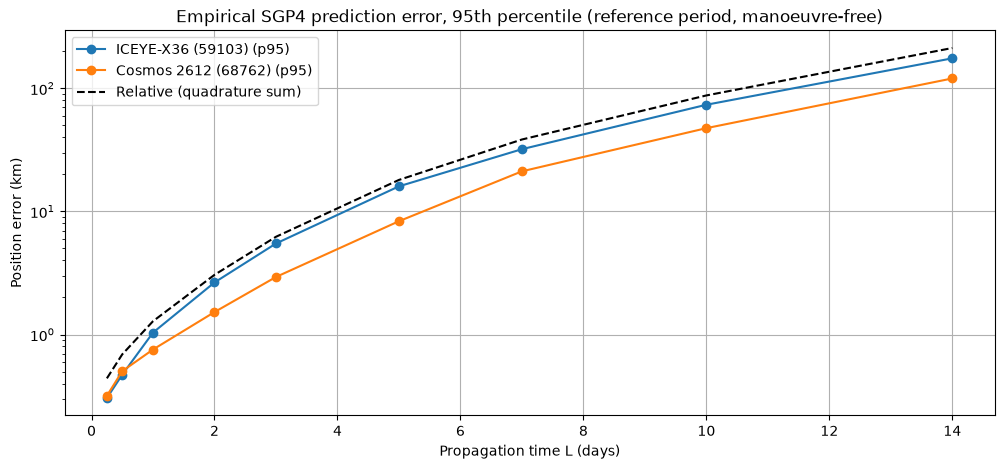

In [9]:
def prediction_error(norad):
    sub = tles[norad]
    sub = sub[sub["epoch"] < REFERENCE_END].reset_index(drop=True)
    ep = _ns(sub["epoch"])
    ev = events[norad]
    rows = []
    for k in range(len(sub)):
        for L in ERROR_LEADS_DAYS:
            target = ep[k] + L * 86400e9
            j = int(np.clip(np.searchsorted(ep, target), 0, len(ep) - 1))
            if j > 0 and abs(ep[j - 1] - target) < abs(ep[j] - target):
                j -= 1
            if j <= k or abs(ep[j] - target) > 0.25 * 86400e9:
                continue
            t_k, t_j = sub.at[k, "epoch"], sub.at[j, "epoch"]
            if ((ev["end"] > t_k) & (ev["start"] < t_j)).any():
                continue
            r1, _ = propagate(sub.at[k, "sat"], t_j)
            r2, _ = propagate(sub.at[j, "sat"], t_j)
            rows.append({"norad": norad, "lead_days": L, "error_km": np.linalg.norm(r1 - r2)})
    return pd.DataFrame(rows)


df_err = pd.concat([prediction_error(n) for n in NORAD_IDS], ignore_index=True)
error_stats = (df_err.groupby(["lead_days", "norad"])["error_km"]
               .agg(n="size", median="median", p95=lambda x: np.percentile(x, 95))
               .unstack("norad"))
display(error_stats)

p95 = df_err.groupby(["norad", "lead_days"])["error_km"].quantile(0.95).unstack("norad")
p95 = p95.reindex(ERROR_LEADS_DAYS).interpolate(limit_direction="both")
p95["relative"] = np.sqrt(p95[NORAD_A] ** 2 + p95[NORAD_B] ** 2)
p95.to_csv(os.path.join(OUTPUT_DIR, "sgp4_error_p95.csv"))

error_table = p95.T.rename(index={NORAD_A: NAME[NORAD_A], NORAD_B: NAME[NORAD_B], "relative": "Relative"})
error_table.columns = [f"L = {L:g} d" for L in error_table.columns]
error_table.index.name = "95th-percentile error (km)"
display(error_table.round(2))


def err95_rel(lead_days):
    # Linear interpolation; below the first lead the first value is used (conservative)
    return float(np.interp(lead_days, p95.index.values, p95["relative"].values))


fig, ax = plt.subplots()
for n in NORAD_IDS:
    ax.plot(p95.index, p95[n], "o-", color=COLOR[n], label=f"{LABEL[n]} (p95)")
ax.plot(p95.index, p95["relative"], "k--", label="Relative (quadrature sum)")
ax.set_yscale("log")
ax.set_xlabel("Propagation time L (days)")
ax.set_ylabel("Position error (km)")
ax.set_title("Empirical SGP4 prediction error, 95th percentile (reference period, manoeuvre-free)")
ax.legend()
save(fig, "sgp4_error.png")
plt.show()

## 7. Relative orbital geometry

Sustained proximity requires coplanar orbits (plane angle ≈ 0) and nearly equal semi-major axes ($\Delta a \approx 0$). This is a **necessary but not sufficient** condition: two objects deployed together may satisfy it without manoeuvring.

Plane angle: $\cos\theta = \hat{\mathbf h}_A\cdot\hat{\mathbf h}_B$, with $\mathbf h = \mathbf r\times\mathbf v$.

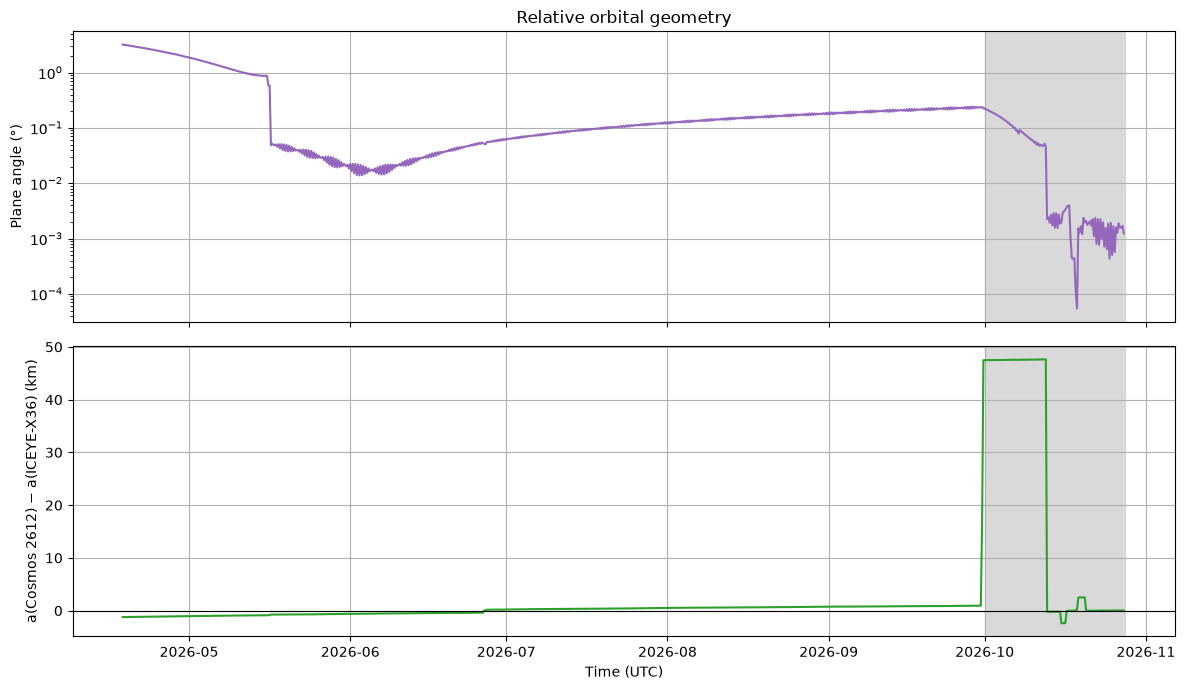

In [10]:
t_geo = pd.date_range(max(tles[NORAD_A]["epoch"].min(), tles[NORAD_B]["epoch"].min()).ceil("6h"),
                      WINDOW_END, freq="6h")
rA, vA, iA, _ = ephemeris(NORAD_A, t_geo)
rB, vB, iB, _ = ephemeris(NORAD_B, t_geo)
hA, hB = np.cross(rA, vA), np.cross(rB, vB)
cos_t = np.einsum("ij,ij->i", hA, hB) / (np.linalg.norm(hA, axis=1) * np.linalg.norm(hB, axis=1))
df_geo = pd.DataFrame({
    "time": t_geo,
    "plane_angle_deg": np.degrees(np.arccos(np.clip(cos_t, -1, 1))),
    "delta_a_km": tles[NORAD_B]["a_km"].values[iB] - tles[NORAD_A]["a_km"].values[iA],
    "delta_inc_deg": tles[NORAD_B]["inc_deg"].values[iB] - tles[NORAD_A]["inc_deg"].values[iA],
})

fig, ax = plt.subplots(2, 1, sharex=True, figsize=(12, 7))
ax[0].plot(df_geo["time"], df_geo["plane_angle_deg"], color="tab:purple")
ax[0].set_ylabel("Plane angle (°)")
ax[0].set_yscale("log")
ax[1].plot(df_geo["time"], df_geo["delta_a_km"], color="tab:green")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_ylabel(f"a({NAME[NORAD_B]}) − a({NAME[NORAD_A]}) (km)")
ax[1].set_xlabel("Time (UTC)")
for a in ax:
    a.axvspan(WINDOW_START, WINDOW_END, color="0.85", zorder=0)
ax[0].set_title("Relative orbital geometry")
fig.tight_layout()
save(fig, "relative_geometry.png")
plt.show()

## 8. Relative distance and closest approach

Sampling every `STEP_S` seconds. The main series uses the `previous` (causal) mode; the `nearest` series is shown for comparison, so that jumps present in only one of them can be identified as TLE-switching artefacts rather than physical motion.

**Relative velocity.** Two magnitudes are reported:

- **Inertial**, $\lVert\mathbf v_B-\mathbf v_A\rVert$, which includes the rotation of the frame: for two objects on the same orbit separated by a distance $d$ it is $\approx n\,d$ (~0.5 km/s at 450 km) even with no relative motion.
- **Local**, as seen from the RIC frame of ICEYE-X36, which rotates with $\boldsymbol\omega=\mathbf h/r^2$:

$$\mathbf v_{loc} = (\mathbf v_B-\mathbf v_A) - \boldsymbol\omega\times(\mathbf r_B-\mathbf r_A)$$

The local velocity describes the relative motion. At large separations it retains a contribution from eccentricity and from the curvature of the rectilinear frame, so it is representative at separations of a few kilometres.

In [11]:
t_win = pd.date_range(WINDOW_START, WINDOW_END, freq=f"{STEP_S}s")
series = {}
for mode in ["previous", "nearest"]:
    rA, vA, _, agA = ephemeris(NORAD_A, t_win, mode)
    rB, vB, _, agB = ephemeris(NORAD_B, t_win, mode)
    series[mode] = dict(rA=rA, vA=vA, rB=rB, vB=vB, age_A=agA, age_B=agB)

S = series["previous"]
df_dist = pd.DataFrame({
    "time": t_win,
    "distance_km": np.linalg.norm(S["rB"] - S["rA"], axis=1),
    "rel_vel_inertial_m_s": 1000 * np.linalg.norm(S["vB"] - S["vA"], axis=1),
    "rel_vel_local_m_s": 1000 * local_rel_velocity(S["rA"], S["vA"], S["rB"], S["vB"]),
    "tle_age_A_h": S["age_A"], "tle_age_B_h": S["age_B"],
    "distance_nearest_km": np.linalg.norm(series["nearest"]["rB"] - series["nearest"]["rA"], axis=1),
})
df_dist.to_csv(os.path.join(OUTPUT_DIR, "distance_1min.csv"), index=False)

df_dist["max_tle_age_h"] = df_dist[["tle_age_A_h", "tle_age_B_h"]].max(axis=1)
df_daily = df_dist.groupby(df_dist["time"].dt.date).agg(
    min_distance_km=("distance_km", "min"), mean_distance_km=("distance_km", "mean"),
    max_distance_km=("distance_km", "max"), min_rel_vel_inertial_m_s=("rel_vel_inertial_m_s", "min"),
    mean_rel_vel_inertial_m_s=("rel_vel_inertial_m_s", "mean"),
    median_rel_vel_local_m_s=("rel_vel_local_m_s", "median"),
    max_tle_age_h=("max_tle_age_h", "max"))
df_daily.index.name = "date"
df_daily.to_csv(os.path.join(OUTPUT_DIR, "daily_summary.csv"))
display(df_daily)

,min_distance_km,mean_distance_km,max_distance_km,min_rel_vel_inertial_m_s,mean_rel_vel_inertial_m_s,median_rel_vel_local_m_s,max_tle_age_h
date,,,,,,,
2026-10-01,"11,367.8987","12,828.6130","13,769.7598","12,404.0746","13,984.7301",81.9848,12.7389
2026-10-02,"13,026.5921","13,671.5167","13,902.3551","14,218.9373","14,903.5807",79.0045,9.5564
2026-10-03,"9,301.2948","11,392.1597","13,024.8133","10,154.0970","12,418.7613",79.4251,9.5522
2026-10-04,"3,445.6321","6,509.6341","9,298.1288","3,765.4300","7,096.1612",78.9529,14.3264
2026-10-05,54.8583,"1,674.1791","3,441.5179",36.0791,"1,823.4991",80.0596,11.1487
2026-10-06,"3,205.5629","6,267.2971","9,116.9499","3,486.1162","6,832.0125",84.0599,9.6516
2026-10-07,"9,120.3787","11,239.2292","12,948.7701","9,932.6743","12,252.2015",82.2998,11.1338
2026-10-08,"12,950.1302","13,639.2133","13,903.0538","14,105.7686","14,868.5603",79.0904,11.1420
2026-10-09,"11,526.4679","12,916.7967","13,817.4912","12,544.2477","14,081.0529",77.6144,12.7341


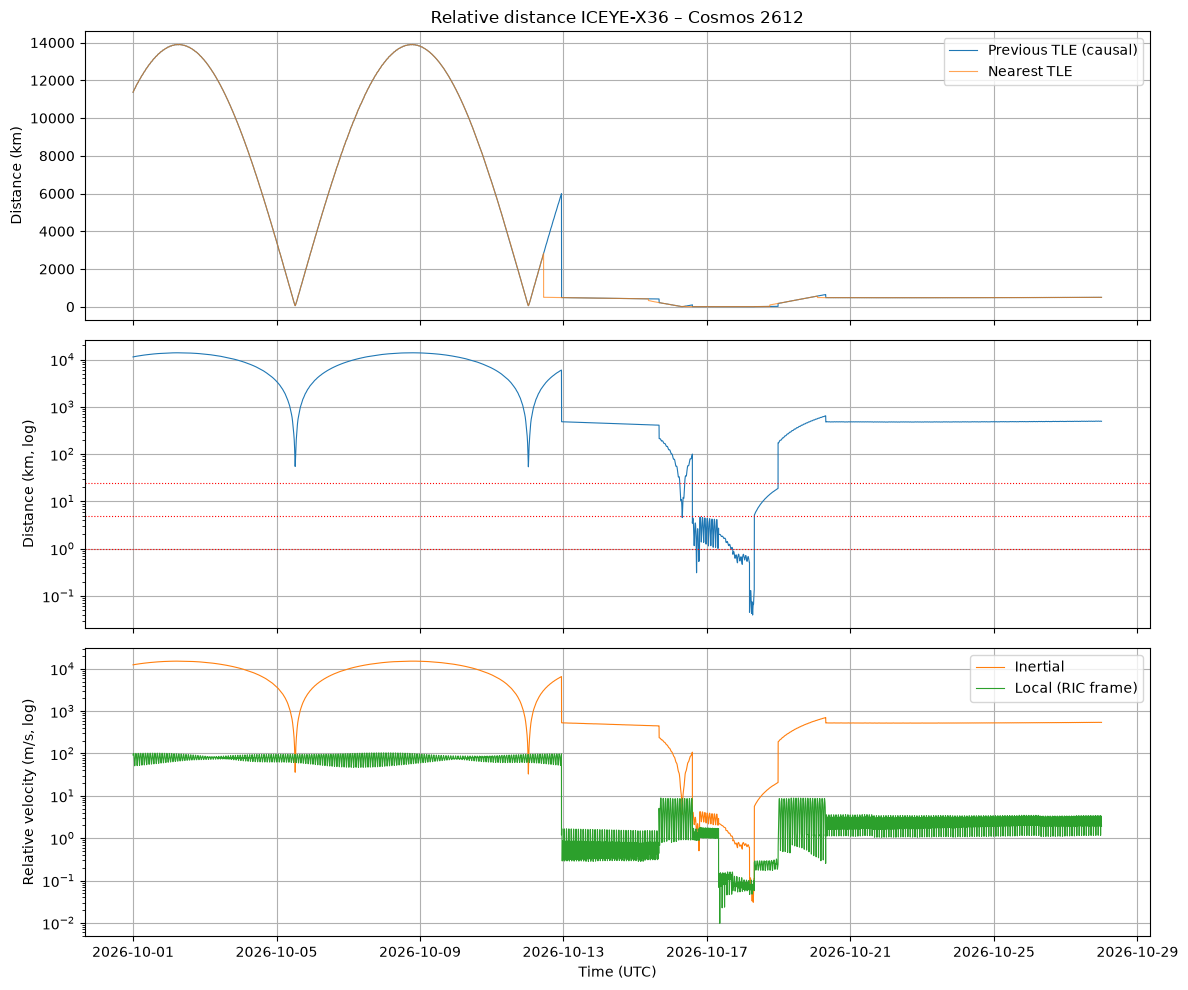

In [12]:
fig, ax = plt.subplots(3, 1, sharex=True, figsize=(12, 10))
ax[0].plot(df_dist["time"], df_dist["distance_km"], lw=0.8, label="Previous TLE (causal)")
ax[0].plot(df_dist["time"], df_dist["distance_nearest_km"], lw=0.8, alpha=0.7, label="Nearest TLE")
ax[0].set_ylabel("Distance (km)")
ax[0].legend()
ax[0].set_title(f"Relative distance {NAME[NORAD_A]} – {NAME[NORAD_B]}")
ax[1].semilogy(df_dist["time"], df_dist["distance_km"], lw=0.8)
for u in THRESHOLDS_KM:
    ax[1].axhline(u, color="red", ls=":", lw=0.8)
ax[1].set_ylabel("Distance (km, log)")
ax[2].semilogy(df_dist["time"], df_dist["rel_vel_inertial_m_s"], lw=0.8, color="tab:orange", label="Inertial")
ax[2].semilogy(df_dist["time"], df_dist["rel_vel_local_m_s"], lw=0.8, color="tab:green", label="Local (RIC frame)")
ax[2].set_ylabel("Relative velocity (m/s, log)")
ax[2].legend()
ax[2].set_xlabel("Time (UTC)")
fig.tight_layout()
save(fig, "distance_window.png")
plt.show()

### Time of closest approach (TCA) and time in proximity

The TCA is first located on the 1-minute grid and then refined at 1-s resolution within ±30 min using the same TLEs. The uncertainty (p95) is the empirical error of Section 6 evaluated at the age of the TLEs at TCA.

In [13]:
k_tca = int(np.nanargmin(df_dist["distance_km"].values))
tca_grid = df_dist["time"].iloc[k_tca]

t_fine = pd.date_range(tca_grid - pd.Timedelta(minutes=30), tca_grid + pd.Timedelta(minutes=30), freq="1s")
rAf, vAf, _, agAf = ephemeris(NORAD_A, t_fine)
rBf, vBf, _, agBf = ephemeris(NORAD_B, t_fine)
d_fine = np.linalg.norm(rBf - rAf, axis=1)
kf = int(np.nanargmin(d_fine))
TCA = t_fine[kf]
d_tca = d_fine[kf]
v_tca = 1000 * np.linalg.norm(vBf[kf] - vAf[kf])
v_tca_loc = 1000 * local_rel_velocity(rAf[kf:kf + 1], vAf[kf:kf + 1], rBf[kf:kf + 1], vBf[kf:kf + 1])[0]
sigma_tca = err95_rel(max(agAf[kf], agBf[kf]) / 24)


def time_below(times, d, threshold):
    m = np.asarray(d < threshold)
    if not m.any():
        return 0.0, 0.0, None, None
    changes = np.diff(np.r_[0, m.astype(int), 0])
    starts, ends = np.where(changes == 1)[0], np.where(changes == -1)[0]
    lengths = ends - starts
    j = int(np.argmax(lengths))
    step_h = STEP_S / 3600
    return m.sum() * step_h, lengths[j] * step_h, times.iloc[starts[j]], times.iloc[ends[j] - 1]


print("=== CLOSEST APPROACH IN THE ANALYSIS WINDOW ===")
print(f"TCA (refined)               : {TCA:%Y-%m-%d %H:%M:%S} UTC")
print(f"Minimum distance            : {d_tca:.3f} km  (SGP4 p95 uncertainty ≈ {sigma_tca:.2f} km)")
print(f"Relative velocity at TCA    : {v_tca_loc:.3f} m/s local ({v_tca:.3f} m/s inertial)")
print(f"TLE age                     : {NAME[NORAD_A]} {agAf[kf]:.1f} h, {NAME[NORAD_B]} {agBf[kf]:.1f} h")
if d_tca < sigma_tca:
    print("The minimum distance is below the uncertainty: only d < "
          f"{d_tca + sigma_tca:.2f} km (p95) can be stated, not its exact value.")

rows = []
for u in THRESHOLDS_KM:
    tot, mx, t0, t1 = time_below(df_dist["time"], df_dist["distance_km"], u)
    sub = df_dist[df_dist["distance_km"] < u]
    rows.append({"threshold_km": u, "total_hours": tot, "longest_run_h": mx, "run_start": t0, "run_end": t1,
                 "median_rel_vel_local_m_s": sub["rel_vel_local_m_s"].median() if len(sub) else np.nan,
                 "p90_rel_vel_local_m_s": sub["rel_vel_local_m_s"].quantile(0.9) if len(sub) else np.nan})
df_prox = pd.DataFrame(rows)
display(df_prox)

pd.DataFrame([{"TCA": TCA, "d_min_km": d_tca, "uncertainty_p95_km": sigma_tca, "rel_vel_local_m_s": v_tca_loc,
               "rel_vel_inertial_m_s": v_tca,
               "tle_age_A_h": agAf[kf], "tle_age_B_h": agBf[kf]}]).to_csv(
    os.path.join(OUTPUT_DIR, "tca.csv"), index=False)

=== CLOSEST APPROACH IN THE ANALYSIS WINDOW ===
TCA (refined)               : 2026-10-18 06:33:14 UTC
Minimum distance            : 0.039 km  (SGP4 p95 uncertainty ≈ 0.75 km)
Relative velocity at TCA    : 0.081 m/s local (0.064 m/s inertial)
TLE age                     : ICEYE-X36 2.1 h, Cosmos 2612 13.2 h
The minimum distance is below the uncertainty: only d < 0.79 km (p95) can be stated, not its exact value.


,threshold_km,total_hours,longest_run_h,run_start,run_end,median_rel_vel_local_m_s,p90_rel_vel_local_m_s
0,1.0000,16.0667,14.5833,2026-10-17 17:04:00+00:00,2026-10-18 07:38:00+00:00,0.0827,0.1261
1,5.0000,41.5500,41.4000,2026-10-16 14:15:00+00:00,2026-10-18 07:38:00+00:00,0.1344,1.6237
2,25.0000,60.6500,57.3333,2026-10-16 14:15:00+00:00,2026-10-18 23:34:00+00:00,0.2345,1.6449


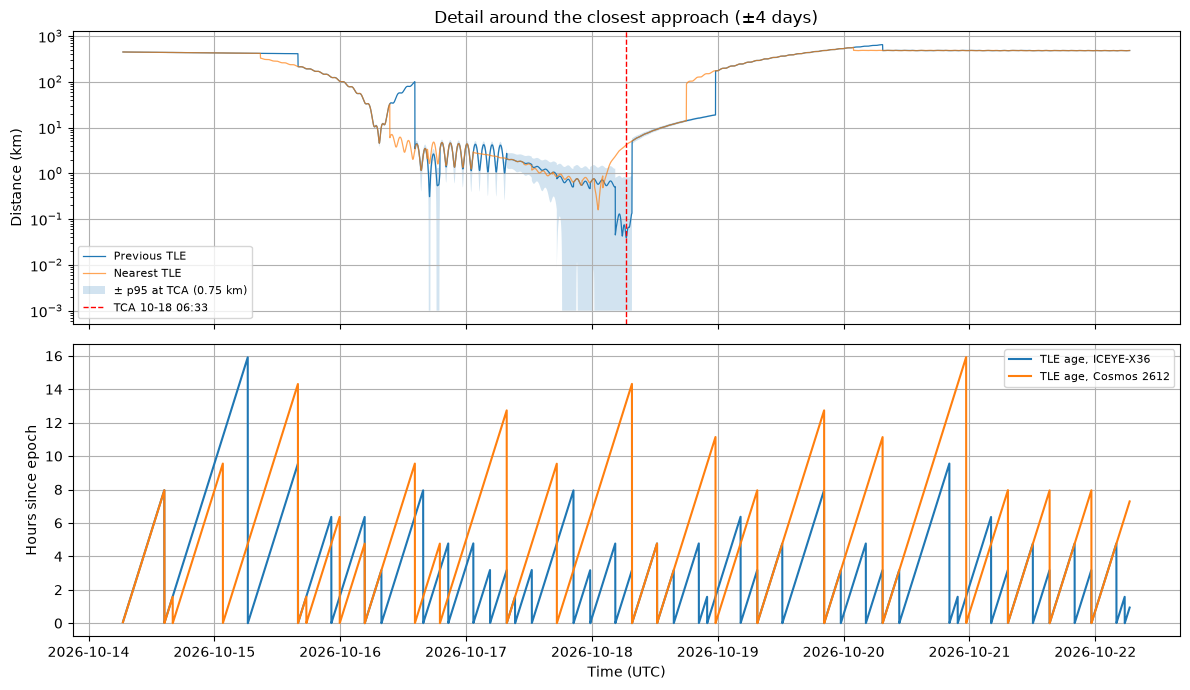

In [14]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(12, 7))
z = df_dist[(df_dist["time"] >= TCA - pd.Timedelta(days=4)) & (df_dist["time"] <= TCA + pd.Timedelta(days=4))]
ax[0].semilogy(z["time"], z["distance_km"], lw=0.9, label="Previous TLE")
ax[0].semilogy(z["time"], z["distance_nearest_km"], lw=0.9, alpha=0.7, label="Nearest TLE")
ax[0].fill_between(z["time"], np.maximum(z["distance_km"] - sigma_tca, 1e-3), z["distance_km"] + sigma_tca,
                   alpha=0.2, label=f"± p95 at TCA ({sigma_tca:.2f} km)")
ax[0].axvline(TCA, color="red", ls="--", lw=1, label=f"TCA {TCA:%m-%d %H:%M}")
ax[0].set_ylabel("Distance (km)")
ax[0].legend(fontsize=8)
ax[0].set_title("Detail around the closest approach (±4 days)")
ax[1].plot(z["time"], z["tle_age_A_h"], color=COLOR[NORAD_A], label=f"TLE age, {NAME[NORAD_A]}")
ax[1].plot(z["time"], z["tle_age_B_h"], color=COLOR[NORAD_B], label=f"TLE age, {NAME[NORAD_B]}")
ax[1].set_ylabel("Hours since epoch")
ax[1].set_xlabel("Time (UTC)")
ax[1].legend(fontsize=8)
fig.tight_layout()
save(fig, "distance_tca_detail.png")
plt.show()

## 9. Relative motion in the RIC frame

Position of Cosmos 2612 relative to ICEYE-X36 in the local frame of ICEYE-X36:

$$\hat{\mathbf R} = \frac{\mathbf r_A}{\lVert\mathbf r_A\rVert},\quad \hat{\mathbf C} = \frac{\mathbf r_A\times\mathbf v_A}{\lVert\mathbf r_A\times\mathbf v_A\rVert},\quad \hat{\mathbf I} = \hat{\mathbf C}\times\hat{\mathbf R}$$

Under natural drift with $\Delta a \neq 0$, the in-track separation grows approximately linearly ($\dot I \approx -\tfrac{3}{2} n\,\Delta a$) without changing direction. A reversal of the drift, or a mean radial offset changing sign, indicates a change in $\Delta a$.

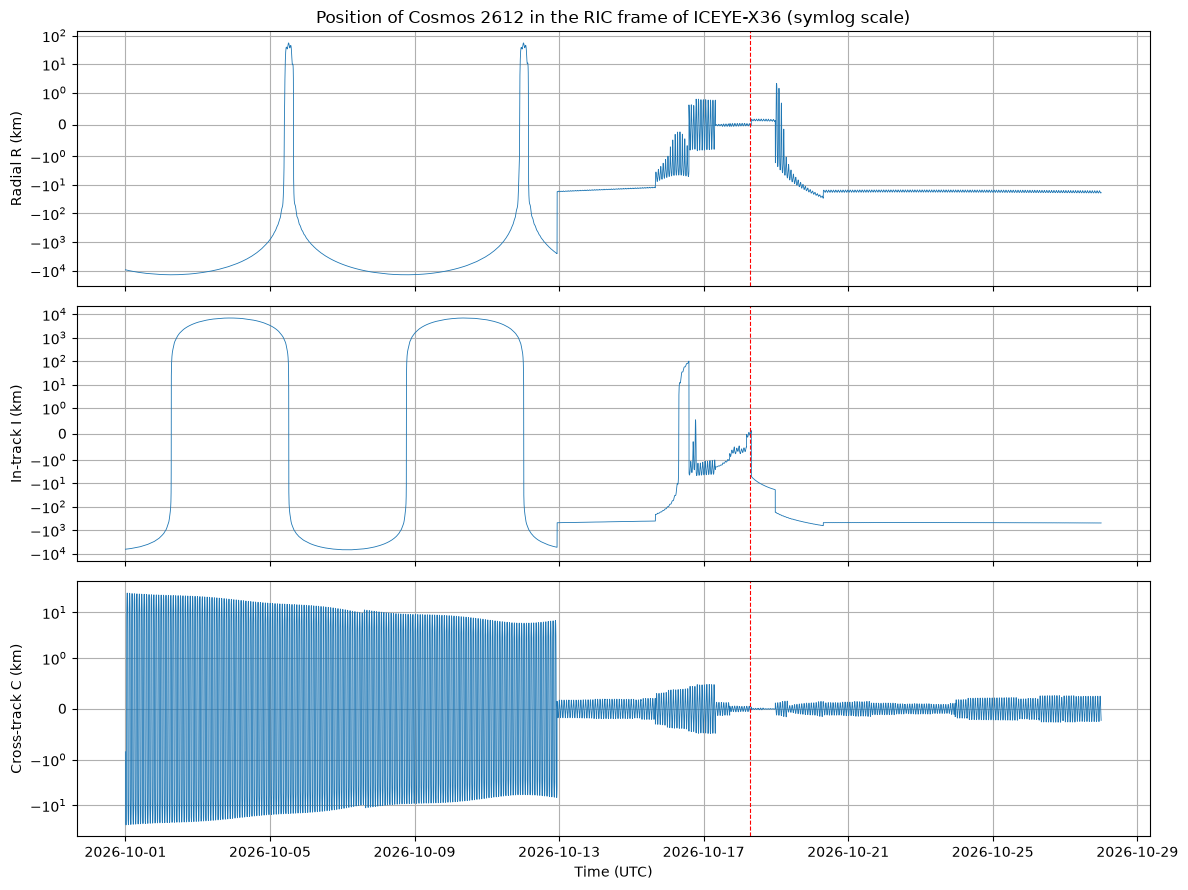

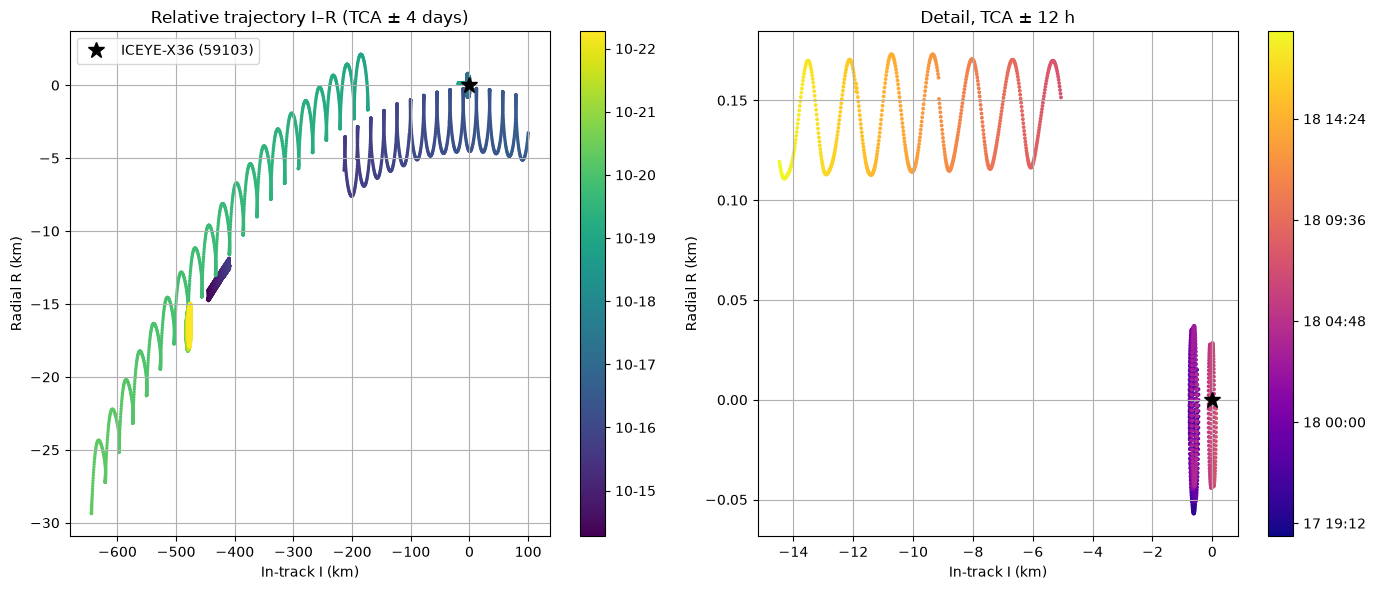

In [15]:
def to_ric(rA, vA, rB):
    R = rA / np.linalg.norm(rA, axis=1)[:, None]
    C = np.cross(rA, vA)
    C /= np.linalg.norm(C, axis=1)[:, None]
    I = np.cross(C, R)
    dr = rB - rA
    return np.einsum("ij,ij->i", dr, R), np.einsum("ij,ij->i", dr, I), np.einsum("ij,ij->i", dr, C)


ric_R, ric_I, ric_C = to_ric(S["rA"], S["vA"], S["rB"])
df_dist["R_km"], df_dist["I_km"], df_dist["C_km"] = ric_R, ric_I, ric_C

fig, ax = plt.subplots(3, 1, sharex=True, figsize=(12, 9))
for a, col, name in zip(ax, ["R_km", "I_km", "C_km"], ["Radial R", "In-track I", "Cross-track C"]):
    a.plot(df_dist["time"], df_dist[col], lw=0.6)
    a.set_yscale("symlog", linthresh=1)
    a.set_ylabel(f"{name} (km)")
    a.axvline(TCA, color="red", ls="--", lw=0.8)
ax[0].set_title(f"Position of {NAME[NORAD_B]} in the RIC frame of {NAME[NORAD_A]} (symlog scale)")
ax[2].set_xlabel("Time (UTC)")
fig.tight_layout()
save(fig, "ric_window.png")
plt.show()

z = df_dist[(df_dist["time"] >= TCA - pd.Timedelta(days=4)) & (df_dist["time"] <= TCA + pd.Timedelta(days=4))]
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sc = ax[0].scatter(z["I_km"], z["R_km"], c=mdates.date2num(z["time"]), s=2, cmap="viridis")
ax[0].plot(0, 0, "k*", ms=12, label=LABEL[NORAD_A])
ax[0].set_xlabel("In-track I (km)")
ax[0].set_ylabel("Radial R (km)")
ax[0].set_title("Relative trajectory I–R (TCA ± 4 days)")
ax[0].legend()
cb = fig.colorbar(sc, ax=ax[0])
cb.ax.yaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
zz = z[(z["time"] >= TCA - pd.Timedelta(hours=12)) & (z["time"] <= TCA + pd.Timedelta(hours=12))]
sc2 = ax[1].scatter(zz["I_km"], zz["R_km"], c=mdates.date2num(zz["time"]), s=3, cmap="plasma")
ax[1].plot(0, 0, "k*", ms=12)
ax[1].set_xlabel("In-track I (km)")
ax[1].set_ylabel("Radial R (km)")
ax[1].set_title("Detail, TCA ± 12 h")
cb2 = fig.colorbar(sc2, ax=ax[1])
cb2.ax.yaxis.set_major_formatter(mdates.DateFormatter("%d %H:%M"))
fig.tight_layout()
save(fig, "ric_trajectory.png")
plt.show()

### Encounter chronology

Values quoted in the article for each phase of the encounter, computed from the TLEs and the causal distance series above, and the cumulative Δv of Cosmos 2612 since May.

- **Phasing drift (1–10 Oct):** median altitude difference, median mean motions, synodic period /|n_A-n_B|$ and median local relative velocity.
- **Far parking (13–14 Oct)**, **approach (15–16 Oct)** and **retreat (18–27 Oct):** separations and altitude offsets.
- **Stale-TLE intervals:** between two Cosmos 2612 TLEs that bracket a manoeuvre, the causal series propagates the pre-manoeuvre TLE and can place Cosmos 2612 at positions that the next TLE contradicts (for example, ahead of ICEYE-X36). An interval is flagged when the causal and nearest series differ by more than 5 km or when Cosmos 2612 appears more than 1 km ahead. The along-track range is reported with and without these intervals.
- **Δv since May:** totals of the events with  > 20$ (Table 3 of the article) and of all detected events.

In [16]:
# Encounter chronology: values quoted in the article (phases, Δv totals)
def _utc(s):
    return pd.Timestamp(s, tz="UTC")


def tle_median(norad, col, t0, t1):
    s = tles[norad]
    return float(s.loc[(s["epoch"] >= _utc(t0)) & (s["epoch"] < _utc(t1)), col].median())


def dist_stats(t0, t1):
    m = (df_dist["time"] >= _utc(t0)) & (df_dist["time"] < _utc(t1))
    return df_dist.loc[m, "distance_km"], df_dist.loc[m, "rel_vel_local_m_s"]


rows = []
# 1. Phasing drift (1-10 October): altitude difference, mean motions, synodic period, local velocity
dh = tle_median(NORAD_B, "mean_alt_km", "2026-10-01", "2026-10-10") - tle_median(NORAD_A, "mean_alt_km", "2026-10-01", "2026-10-10")
nA = tle_median(NORAD_A, "n_rev_day", "2026-10-01", "2026-10-10")
nB = tle_median(NORAD_B, "n_rev_day", "2026-10-01", "2026-10-10")
_, v = dist_stats("2026-10-01", "2026-10-10")
rows += [("Drift: altitude B - A (km)", dh), ("Drift: mean motion A (rev/day)", nA), ("Drift: mean motion B (rev/day)", nB),
         ("Drift: synodic period (days)", 1 / abs(nA - nB)), ("Drift: median local velocity (m/s)", v.median())]
# 2. Far parking (13-14 October)
d, v = dist_stats("2026-10-13", "2026-10-15")
rows += [("Parking: median separation (km)", d.median()), ("Parking: median local velocity (m/s)", v.median())]
# 3. Approach (15-16 October): separation at the start; altitude offset of B
d, _ = dist_stats("2026-10-15", "2026-10-16")
rows += [("Approach: separation at start of 15 Oct (km)", d.iloc[0]),
         ("Approach: altitude B - A, 15-16 Oct (km)", tle_median(NORAD_B, "mean_alt_km", "2026-10-15", "2026-10-16T12")
          - tle_median(NORAD_A, "mean_alt_km", "2026-10-15", "2026-10-16T12"))]
# 4. Retreat: altitude offset, end of the retreat and later drift
rows += [("Retreat: altitude B - A, 18T12-20 Oct (km)", tle_median(NORAD_B, "mean_alt_km", "2026-10-18T12", "2026-10-20")
          - tle_median(NORAD_A, "mean_alt_km", "2026-10-18T12", "2026-10-20"))]
d, _ = dist_stats("2026-10-20T12", "2026-10-23T12")
rows += [("Retreat: median separation 20 Oct 12 UTC - 23 Oct 12 UTC (km)", d.median())]
late = df_dist[df_dist["time"] >= _utc("2026-10-23T12")]
slope = np.polyfit((late["time"] - late["time"].iloc[0]).dt.total_seconds() / 86400, late["distance_km"], 1)[0]
rows += [("Retreat: drift rate from 23 Oct 12 UTC (km/day)", slope),
         ("Retreat: separation at end of window (km)", df_dist["distance_km"].iloc[-1])]

# 5. Along-track position of B in the RIC frame of A (13-27 October).
# Between two Cosmos 2612 TLEs that bracket a manoeuvre, the causal series propagates the pre-manoeuvre TLE and
# can place B at positions that the next TLE contradicts. Such intervals are flagged when the causal and nearest
# series differ by > 5 km, or when B appears > 1 km ahead of A (beyond the data resolution).
t = df_dist["time"]
m13 = (t >= _utc("2026-10-13")).values
epB = tles[NORAD_B]["epoch"]
epB = epB[(epB >= _utc("2026-10-12")) & (epB <= WINDOW_END)].tolist() + [WINDOW_END + pd.Timedelta(days=1)]
gap = np.abs(df_dist["distance_km"] - df_dist["distance_nearest_km"]).values
stale = np.zeros(len(t), bool)
for e0, e1 in zip(epB[:-1], epB[1:]):
    w = ((t >= e0) & (t < e1)).values & m13
    if w.any() and (np.nanmax(gap[w]) > 5 or np.nanmax(ric_I[w]) > 1):
        stale |= w
        rows += [(f"Stale-TLE interval {e0:%d %b %H:%M} - {e1:%d %b %H:%M}: in-track min / max (km)",
                  f"{np.nanmin(ric_I[w]):.1f} / {np.nanmax(ric_I[w]):.1f}")]
ok = m13 & ~stale
rows += [("RIC in-track, 13-27 Oct, other intervals: min (km)", np.nanmin(ric_I[ok])),
         ("RIC in-track, 13-27 Oct, other intervals: max (km)", np.nanmax(ric_I[ok]))]
# 6. Cumulative Δv of Cosmos 2612 since May
evB = df_events[(df_events["norad"] == NORAD_B) & (df_events["start"] >= _utc("2026-05-01"))]
big = evB[evB["z_max"] > 20]
plane = float(big.loc[big["di_net_deg"].abs().idxmax(), "dv_net_m_s"])
for name, e in [("z > 20 events (Table 3)", big), ("all events", evB)]:
    rows += [(f"Δv since May, {name}: net (m/s)", e["dv_net_m_s"].sum()),
             (f"Δv since May, {name}: gross (m/s)", e["dv_gross_m_s"].sum())]
rows += [("Plane match share of total Δv, all events (%)", 100 * plane / evB["dv_gross_m_s"].sum()),
         ("Plane match share of total Δv, all events, net (%)", 100 * plane / evB["dv_net_m_s"].sum())]

df_chrono = pd.DataFrame(rows, columns=["quantity", "value"])
df_chrono.to_csv(os.path.join(OUTPUT_DIR, "encounter_chronology.csv"), index=False)
print(df_chrono.to_string(index=False, formatters={"value": lambda x: f"{x:.3f}" if isinstance(x, float) else str(x)}))

                                                               quantity           value
                                             Drift: altitude B - A (km)         47.5389
                                         Drift: mean motion A (rev/day)         15.0773
                                         Drift: mean motion B (rev/day)         14.9233
                                           Drift: synodic period (days)          6.4958
                                     Drift: median local velocity (m/s)         79.4465
                                        Parking: median separation (km)        453.9082
                                   Parking: median local velocity (m/s)          0.7038
                           Approach: separation at start of 15 Oct (km)        426.8085
                               Approach: altitude B - A, 15-16 Oct (km)         -2.3939
                             Retreat: altitude B - A, 18T12-20 Oct (km)          2.4950
          Retreat: median separa

## 10. Test R1: ballistic counterfactual

For each lead time $L$, the last TLEs of **both** objects with epoch ≤ TCA − $L$ are propagated without manoeuvres up to TCA + 2 days. Under H0, the predicted relative position at TCA must match the observed one within the prediction error:

$$\delta_L = \left\lVert \Delta\mathbf r_{bal}(TCA) - \Delta\mathbf r_{obs}(TCA) \right\rVert \le K_{err}\cdot \varepsilon_{95}(L_{eff})$$

where $L_{eff}$ is the time between the oldest TLE used and TCA, and $\varepsilon_{95}$ also includes the error of the observation itself. Agreement is expected for short leads, which serves as a check of the method; under H1, rejection appears from the lead at which the cut-off precedes the manoeuvre.

In [17]:
t_cf = pd.date_range(TCA - pd.Timedelta(days=2), TCA + pd.Timedelta(days=2), freq=f"{STEP_S}s")
rAo, vAo, _, agAo = ephemeris(NORAD_A, t_cf)
rBo, vBo, _, agBo = ephemeris(NORAD_B, t_cf)
k0 = int(np.argmin(np.abs(_ns(t_cf) - _ns([TCA])[0])))
drel_obs = rBo - rAo
d_obs = np.linalg.norm(drel_obs, axis=1)
err_obs = err95_rel(max(agAo[k0], agBo[k0]) / 24)

t_plot_start = TCA - pd.Timedelta(days=max(CF_LEADS_DAYS) + 1)
t_plot = pd.date_range(t_plot_start, TCA + pd.Timedelta(days=2), freq="120s")
rAp, _, _, _ = ephemeris(NORAD_A, t_plot)
rBp, _, _, _ = ephemeris(NORAD_B, t_plot)

rows, curves = [], {}
for L in CF_LEADS_DAYS:
    cutoff = TCA - pd.Timedelta(days=L)
    iA = int(np.searchsorted(EPOCHS_NS[NORAD_A], _ns([cutoff])[0], side="right") - 1)
    iB = int(np.searchsorted(EPOCHS_NS[NORAD_B], _ns([cutoff])[0], side="right") - 1)
    if iA < 0 or iB < 0:
        continue
    epA, epB = tles[NORAD_A].at[iA, "epoch"], tles[NORAD_B].at[iB, "epoch"]
    L_eff = (TCA - min(epA, epB)).total_seconds() / 86400
    rAb, vAb, _, _ = ephemeris(NORAD_A, t_cf, fixed_row=iA)
    rBb, vBb, _, _ = ephemeris(NORAD_B, t_cf, fixed_row=iB)
    d_bal = np.linalg.norm(rBb - rAb, axis=1)
    delta = np.linalg.norm((rBb - rAb)[k0] - drel_obs[k0])
    eps = np.hypot(err95_rel(L_eff), err_obs)
    kb = int(np.nanargmin(d_bal))
    ev_between = df_events[(df_events["end"] > min(epA, epB)) & (df_events["start"] < TCA)]
    rows.append({
        "lead_days": L, "effective_lead_days": L_eff, "tle_epoch_A": epA, "tle_epoch_B": epB,
        "d_bal_at_TCA_km": d_bal[k0], "d_obs_at_TCA_km": d_obs[k0],
        "discrepancy_km": delta, "eps95_km": eps, "ratio": delta / eps,
        "rejects_H0": delta > K_ERR * eps,
        "d_min_bal_4d_km": d_bal[kb], "time_min_bal": t_cf[kb],
        "manoeuvres_reduce_distance": np.nanmin(d_obs) + K_ERR * eps < d_bal[kb],
        "rel_vel_at_min_bal_m_s": 1000 * np.linalg.norm(vBb[kb] - vAb[kb]),
        "hours_bal_<5km": (d_bal < 5).sum() * STEP_S / 3600,
        "events_between_cutoff_and_TCA": ", ".join(f"{int(r.norad)}@{r.start:%m-%d}" for r in ev_between.itertuples()) or "-",
    })
    tp = t_plot[t_plot >= min(epA, epB)]
    rAc, _, _, _ = ephemeris(NORAD_A, tp, fixed_row=iA)
    rBc, _, _, _ = ephemeris(NORAD_B, tp, fixed_row=iB)
    curves[L] = (tp, np.linalg.norm(rBc - rAc, axis=1))

df_cf = pd.DataFrame(rows)
df_cf.to_csv(os.path.join(OUTPUT_DIR, "test_R1_counterfactual.csv"), index=False)
obs_hours5 = (d_obs < 5).sum() * STEP_S / 3600
print(f"Observed in TCA ± 2 d: d_min = {d_obs.min():.3f} km, hours < 5 km = {obs_hours5:.1f} h, "
      f"observation p95 error = {err_obs:.2f} km")
display(df_cf)

Observed in TCA ± 2 d: d_min = 0.039 km, hours < 5 km = 41.6 h, observation p95 error = 0.75 km


,lead_days,effective_lead_days,tle_epoch_A,tle_epoch_B,d_bal_at_TCA_km,d_obs_at_TCA_km,discrepancy_km,eps95_km,ratio,rejects_H0,d_min_bal_4d_km,time_min_bal,manoeuvres_reduce_distance,rel_vel_at_min_bal_m_s,hours_bal_<5km,events_between_cutoff_and_TCA
0,0.5000,0.7508,2026-10-17 12:32:03.367680+00:00,2026-10-17 17:18:44.625312+00:00,0.0445,0.0394,0.0343,1.2411,0.0276,False,0.0091,2026-10-20 00:44:14+00:00,False,0.0704,95.2500,"59103@10-17, 68762@10-15"
1,1.0000,1.4808,2026-10-17 04:34:14.733120+00:00,2026-10-16 19:00:52.732800+00:00,3.9744,0.0394,3.9496,2.2633,1.7450,False,0.8303,2026-10-17 18:29:14+00:00,False,1.8316,75.2333,"59103@10-17, 68762@10-15"
2,2.0000,2.0781,2026-10-16 04:40:48.547776+00:00,2026-10-16 04:40:53.110560+00:00,659.1496,0.0394,659.1767,3.3869,194.6244,True,4.5420,2026-10-16 07:27:14+00:00,False,3.6765,0.1500,"59103@10-17, 68762@10-15"
3,3.0000,3.2056,2026-10-15 06:22:55.687584+00:00,2026-10-15 01:37:10.298784+00:00,344.8945,0.0394,344.8691,7.4776,46.1202,True,302.4656,2026-10-20 06:15:14+00:00,True,331.8250,0.0000,"59103@10-17, 68762@10-15"
4,5.0000,5.3299,2026-10-12 22:38:11.772384+00:00,2026-10-12 22:39:15.602112+00:00,341.5047,0.0394,341.4792,21.4109,15.9488,True,296.7079,2026-10-20 06:15:14+00:00,True,325.5262,0.0000,"59103@10-17, 68762@10-10, 68762@10-15"
5,7.0000,7.3319,2026-10-11 05:13:30.420480+00:00,2026-10-10 22:35:20.989824+00:00,"1,563.8037",0.0394,"1,563.8318",43.8624,35.6531,True,54.8356,2026-10-18 12:10:14+00:00,False,37.1540,0.0000,"59103@10-09, 59103@10-17, 68762@10-10, 68762@1..."
6,10.0000,10.3491,2026-10-08 03:57:27.051552+00:00,2026-10-07 22:10:29.499456+00:00,"1,645.8717",0.0394,"1,645.8996",98.5174,16.7067,True,56.3244,2026-10-18 12:27:14+00:00,False,33.5864,0.0000,"59103@10-09, 59103@10-17, 68762@10-10, 68762@1..."


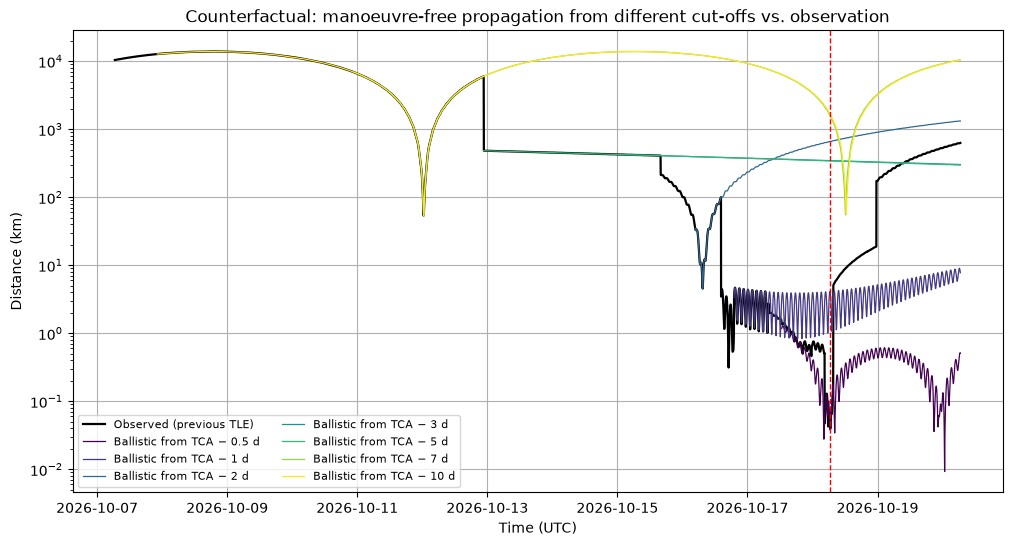

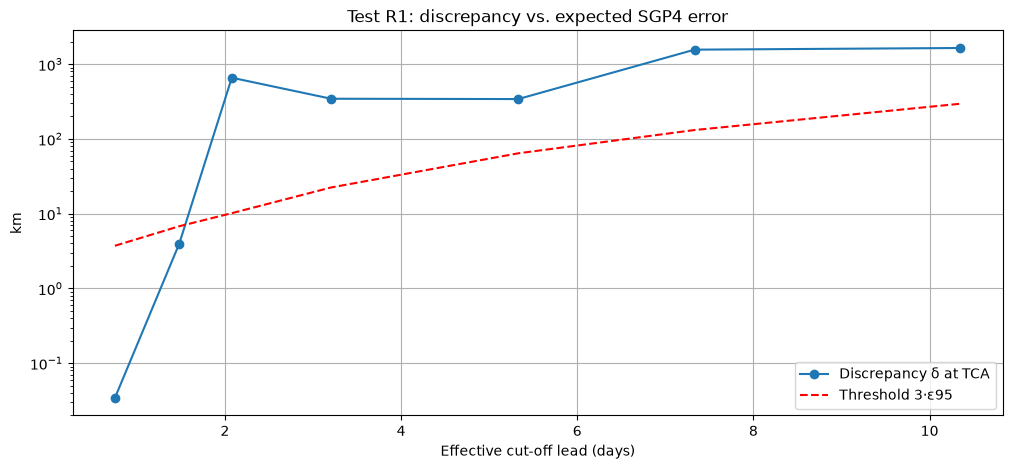

In [18]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.semilogy(t_plot, np.linalg.norm(rBp - rAp, axis=1), color="k", lw=1.6, label="Observed (previous TLE)")
cmap = plt.get_cmap("viridis", len(curves))
for j, (L, (tp, dd)) in enumerate(curves.items()):
    ax.semilogy(tp, dd, lw=0.9, color=cmap(j), label=f"Ballistic from TCA − {L:g} d")
ax.axvline(TCA, color="red", ls="--", lw=1)
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Distance (km)")
ax.set_title("Counterfactual: manoeuvre-free propagation from different cut-offs vs. observation")
ax.legend(fontsize=8, ncol=2)
save(fig, "counterfactual_distance.png")
plt.show()

fig, ax = plt.subplots()
ax.semilogy(df_cf["effective_lead_days"], df_cf["discrepancy_km"], "o-", label="Discrepancy δ at TCA")
ax.semilogy(df_cf["effective_lead_days"], K_ERR * df_cf["eps95_km"], "r--", label=f"Threshold {K_ERR:g}·ε95")
ax.set_xlabel("Effective cut-off lead (days)")
ax.set_ylabel("km")
ax.set_title("Test R1: discrepancy vs. expected SGP4 error")
ax.legend()
save(fig, "counterfactual_R1.png")
plt.show()

## 11. Summary figure and verdict with the pre-specified rules

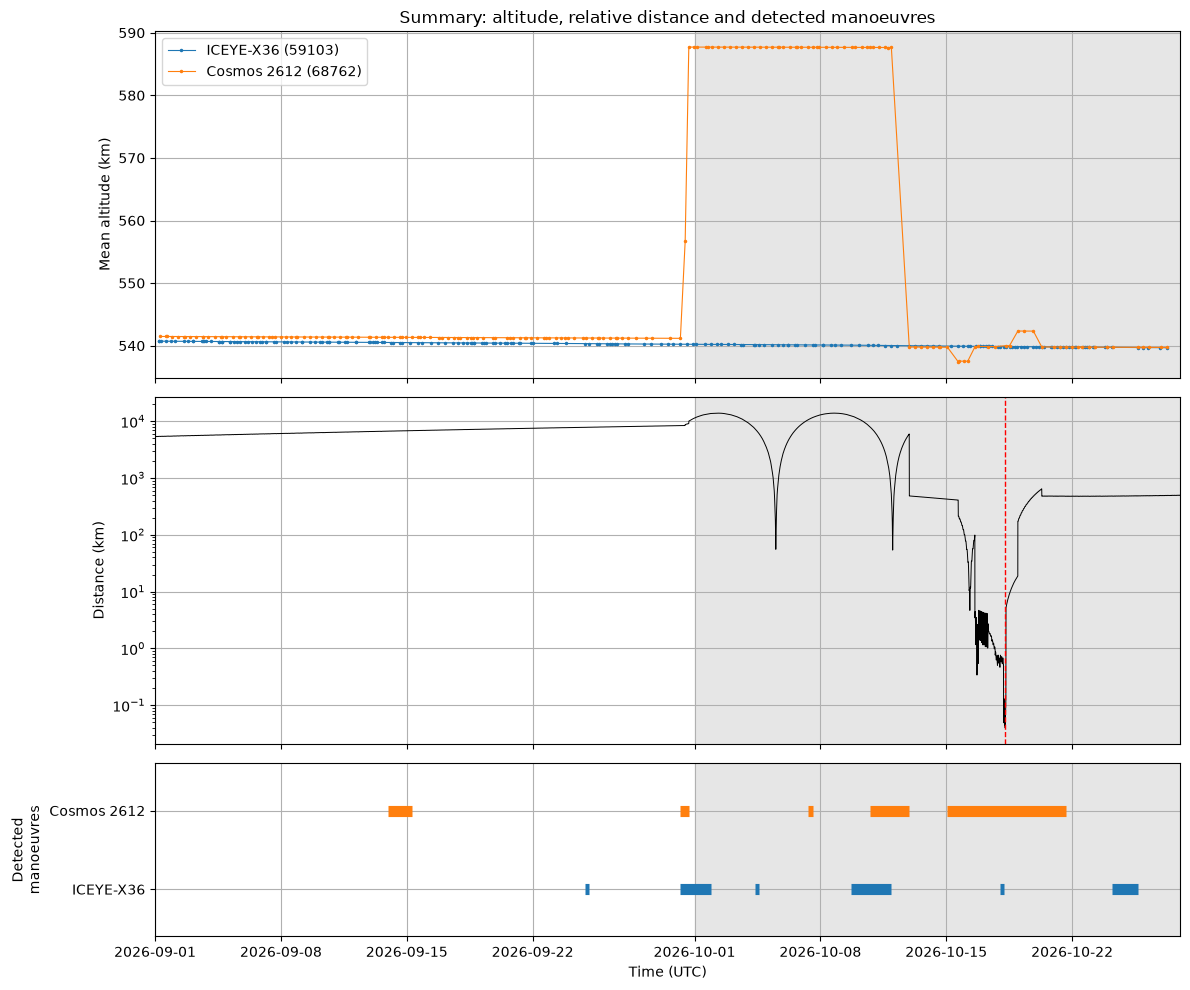

In [19]:
fig, ax = plt.subplots(3, 1, sharex=True, figsize=(12, 10), gridspec_kw={"height_ratios": [2, 2, 1]})
for n in NORAD_IDS:
    sub = tles[n][(tles[n]["epoch"] >= CONTEXT_START) & (tles[n]["epoch"] <= WINDOW_END)]
    ax[0].plot(sub["epoch"], sub["mean_alt_km"], ".-", ms=3, lw=0.8, color=COLOR[n], label=LABEL[n])
ax[0].set_ylabel("Mean altitude (km)")
ax[0].legend()
t_ctx = pd.date_range(CONTEXT_START, WINDOW_END, freq="5min")
rA_, _, _, _ = ephemeris(NORAD_A, t_ctx)
rB_, _, _, _ = ephemeris(NORAD_B, t_ctx)
ax[1].semilogy(t_ctx, np.linalg.norm(rB_ - rA_, axis=1), lw=0.7, color="k")
ax[1].axvline(TCA, color="red", ls="--", lw=1)
ax[1].set_ylabel("Distance (km)")
for j, n in enumerate(NORAD_IDS):
    for ev in events[n].itertuples():
        if ev.end >= CONTEXT_START:
            ax[2].plot([ev.start, ev.end], [j, j], lw=8, color=COLOR[n], solid_capstyle="butt")
ax[2].set_yticks([0, 1], [NAME[NORAD_A], NAME[NORAD_B]])
ax[2].set_ylim(-0.6, 1.6)
ax[2].set_ylabel("Detected\nmanoeuvres")
ax[2].set_xlabel("Time (UTC)")
ax[2].set_xlim(CONTEXT_START, WINDOW_END)
for a in ax:
    a.axvspan(WINDOW_START, WINDOW_END, color="0.9", zorder=0)
ax[0].set_title("Summary: altitude, relative distance and detected manoeuvres")
fig.tight_layout()
save(fig, "summary.png")
plt.show()

In [20]:
# Evaluation of the rules defined in Section 0
rej = df_cf[df_cf["rejects_H0"]]
R1 = len(rej) > 0
if R1:
    L_rej = rej["effective_lead_days"].min()
    cutoff = TCA - pd.Timedelta(days=L_rej)
    ev_R2 = df_events[(df_events["end"] > cutoff) & (df_events["start"] < TCA)]
    R3 = bool(rej["manoeuvres_reduce_distance"].all())
else:
    L_rej, ev_R2, R3 = None, df_events.iloc[0:0], False
R2 = len(ev_R2) > 0

print("=" * 78)
print("TEST RESULTS (PRE-SPECIFIED RULES)")
print("=" * 78)
print(f"R1 need for manoeuvres : {'yes, H0 rejected' if R1 else 'no, H0 not rejected'}"
      + (f" (from a cut-off {L_rej:.2f} d before TCA; max δ/ε95 = {df_cf['ratio'].max():.1f} > {K_ERR:g})" if R1
         else f" (max δ/ε95 = {df_cf['ratio'].max():.2f} ≤ {K_ERR:g})"))
if R1:
    print(f"R2 attribution         : {'yes' if R2 else 'no'}"
          + (f" — {len(ev_R2)} event(s) between cut-off and TCA" if R2 else ""))
    for r in rej.itertuples():
        print(f"R3 direction (cut-off {r.effective_lead_days:5.2f} d): observed d_min = {np.nanmin(d_obs):.3f} km, "
              f"ballistic d_min = {r.d_min_bal_4d_km:.3f} km -> "
              f"{'reduces distance' if r.manoeuvres_reduce_distance else 'does not reduce distance'}")

print("\nDESCRIPTIVE")
print(f"  TCA {TCA:%Y-%m-%d %H:%M:%S} UTC, d_min = {d_tca:.3f} km (±{sigma_tca:.2f} km p95), "
      f"local relative velocity = {v_tca_loc:.3f} m/s")
for r in df_prox.itertuples():
    print(f"  < {r.threshold_km:g} km: {r.total_hours:.1f} h in total, longest run {r.longest_run_h:.1f} h")
g_tca = df_geo.iloc[int(np.argmin(np.abs(_ns(df_geo['time']) - _ns([TCA])[0])))]
print(f"  At TCA: plane angle = {g_tca['plane_angle_deg']:.4f}°, Δa = {g_tca['delta_a_km']:.3f} km")
for r in df_rate.itertuples():
    print(f"  Frequency, {r.object}: {r.test_events} events in the test period "
          f"(expected {r.expected_lambda:.2f}, p = {r.p_value:.2e})")
if R2:
    print("\n  Events between cut-off and TCA:")
    for r in ev_R2.itertuples():
        print(f"   {LABEL[r.norad]}: {r.start:%Y-%m-%d %H:%M} → {r.end:%Y-%m-%d %H:%M}, "
              f"Δa = {r.da_net_km:+.3f} km, Δi = {r.di_net_deg:+.4f}°, Δv ≥ {r.dv_net_m_s:.2f} m/s")

print("\nVERDICT (PRE-SPECIFIED RULES)")
if not R1:
    print("  H0 not rejected. The approach is consistent with natural orbital evolution within the SGP4 error.")
elif R2 and R3:
    actors = sorted(ev_R2["norad"].unique())
    print("  H0 rejected. The approach cannot be obtained by ballistic propagation of the prior state; it required")
    print("  manoeuvres, detected for " + ", ".join(LABEL[a] for a in actors) + ", that reduced the distance")
    print("  relative to natural evolution (consistent with H1).")
elif R2:
    print("  Manoeuvres occurred and the trajectory is not ballistic, but they did not reduce the distance")
    print("  relative to natural evolution: the approach cannot be attributed to them.")
else:
    print("  Inconclusive. The trajectory departs from ballistic propagation, but the detector identifies")
    print("  no manoeuvre that explains it.")

TEST RESULTS (PRE-SPECIFIED RULES)
R1 need for manoeuvres : yes, H0 rejected (from a cut-off 2.08 d before TCA; max δ/ε95 = 194.6 > 3)
R2 attribution         : yes — 2 event(s) between cut-off and TCA
R3 direction (cut-off  2.08 d): observed d_min = 0.039 km, ballistic d_min = 4.542 km -> does not reduce distance
R3 direction (cut-off  3.21 d): observed d_min = 0.039 km, ballistic d_min = 302.466 km -> reduces distance
R3 direction (cut-off  5.33 d): observed d_min = 0.039 km, ballistic d_min = 296.708 km -> reduces distance
R3 direction (cut-off  7.33 d): observed d_min = 0.039 km, ballistic d_min = 54.836 km -> does not reduce distance
R3 direction (cut-off 10.35 d): observed d_min = 0.039 km, ballistic d_min = 56.324 km -> does not reduce distance

DESCRIPTIVE
  TCA 2026-10-18 06:33:14 UTC, d_min = 0.039 km (±0.75 km p95), local relative velocity = 0.081 m/s
  < 1 km: 16.1 h in total, longest run 14.6 h
  < 5 km: 41.5 h in total, longest run 41.4 h
  < 25 km: 60.6 h in total, longes

## 12. Revised decision rules

The decision rules of Section 0 were fixed before running the analysis on real data, and two of them were revised after the first run. This section describes the initial version, what was observed when applying it, and the modification adopted. Both verdicts (pre-specified and revised) are kept in this notebook.

**Initial rules.** R3 required the observed minimum distance within TCA ± 2 d to be smaller than the ballistic one, after subtracting $K_{err}\,\varepsilon_{95}$, in *every* cut-off rejecting H0; R2 attributed the approach according to the presence of manoeuvre-detector events with $|z| > 5$ between the cut-off and TCA. With these rules R1 was met (H0 rejected from the 2.08 d cut-off onwards), but the overall verdict was that the approach could not be attributed to the manoeuvres (Section 11).

**What was observed.**

1. R3 was not met in the 2.08, 7.33 and 10.35 d cut-offs. In all of them the manoeuvre-free minimum distance (4.5, 54.8 and 56.3 km) was smaller than $K_{err}\,\varepsilon_{95}$ (10, 132 and 296 km), so the comparison fell below the resolution of the data and could not have been favourable in any scenario.
2. Between the cut-off and TCA the detector flagged events for both objects. Those of ICEYE-X36 occur at the same rate as in the reference period ($p = 0.66$, Section 5) and are very small (Δv of hundredths of m/s), consistent with TLE noise, so the presence of an event was not enough to attribute the approach. A higher z threshold is not stable either, because the scores of noise and of small manoeuvres overlap.

**Modification adopted.**

- **Revised R3:** only cut-offs *with power* are evaluated, i.e. those for which the manoeuvre-free propagation stays outside the 5 km proximity threshold even after subtracting $K_{err}\,\varepsilon_{95}$; this criterion depends only on the propagation error and the ballistic trajectory. The direction is measured by the total time spent within 5 km, observed vs. manoeuvre-free.
- **Revised R2 (per-object counterfactual):** for each cut-off, **only one** object is propagated without manoeuvres while the other is taken as observed. The manoeuvres of object X are *necessary* if, without them, the relative position at TCA departs from the observed one by more than $K_{err}\,\varepsilon_{95,X}$. The test is symmetric and does not depend on the detector.

**R1 was not modified:** the conclusion that the approach required manoeuvres is obtained with both the initial and the revised rules. The revision affects the direction of the effect and the attribution to a specific object.

Because the revision was made after the first result was known, the attribution does not carry the weight of a fully pre-specified test. It is therefore complemented by the parameter sensitivity analysis and negative controls of Section 13 and by the synthetic-data check with known truth (Section 13).

The event tables of Section 5 are kept as descriptive results. The sensitivity of the event count to the z threshold is also reported below.

,effective_lead_days,rejects_H0,has_power,hours_obs_<5km,hours_bal_<5km,increases_proximity,ratio_only_59103,necessary_59103,ratio_only_68762,necessary_68762
0,0.7508,False,False,41.5667,95.2500,False,0.0321,False,0.0000,False
1,1.4808,False,False,41.5667,75.2333,False,0.3938,False,2.5188,False
2,2.0781,True,False,41.5667,0.1500,True,0.1683,False,367.0578,True
3,3.2056,True,True,41.5667,0.0000,True,0.1402,False,96.3993,True
4,5.3299,True,True,41.5667,0.0000,True,0.3848,False,31.9207,True
5,7.3319,True,False,41.5667,0.0000,True,0.2627,False,65.2309,True
6,10.3491,True,False,41.5667,0.0000,True,1.2314,False,28.8133,True


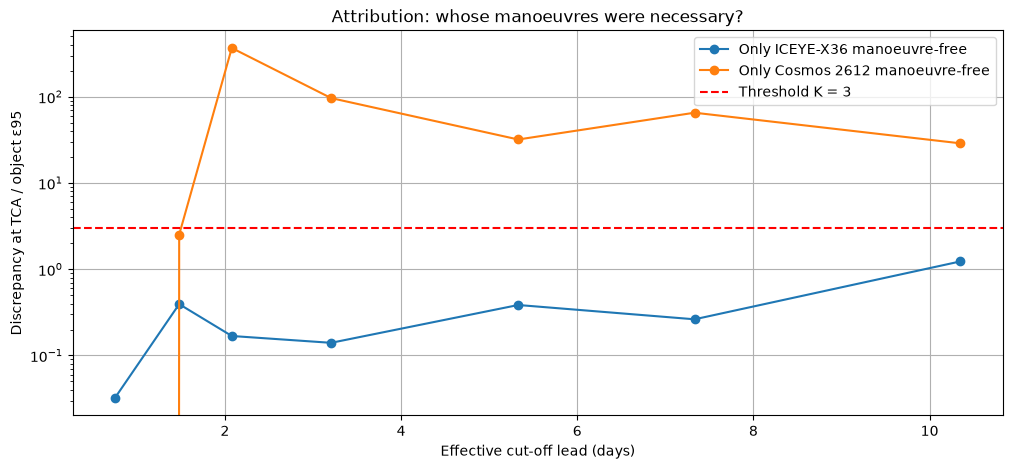

Sensitivity of the event count (1 Sep – 27 Oct) to the z threshold:


,z_threshold,events_ICEYE-X36,events_Cosmos 2612
0,5,6,5
1,10,2,4
2,20,0,4
3,50,0,4
4,100,0,4
5,200,0,4
6,500,0,3
7,1000,0,3


In [21]:
PROX_THRESHOLD_KM = 5.0  # one of THRESHOLDS_KM


def err95_obj(norad, lead_days):
    return float(np.interp(lead_days, p95.index.values, p95[norad].values))


def row_of(norad, epoch):
    return int(tles[norad].index[tles[norad]["epoch"] == epoch][0])


obs_hours = (d_obs < PROX_THRESHOLD_KM).sum() * STEP_S / 3600
rows = []
for _, r in df_cf.iterrows():
    iA, iB = row_of(NORAD_A, r["tle_epoch_A"]), row_of(NORAD_B, r["tle_epoch_B"])
    rAb, _, _, _ = ephemeris(NORAD_A, t_cf, fixed_row=iA)
    rBb, _, _, _ = ephemeris(NORAD_B, t_cf, fixed_row=iB)
    LA = (TCA - r["tle_epoch_A"]).total_seconds() / 86400
    LB = (TCA - r["tle_epoch_B"]).total_seconds() / 86400
    # Only A manoeuvre-free (B as observed) and only B manoeuvre-free (A as observed)
    dA = np.linalg.norm((rBo - rAb)[k0] - drel_obs[k0])
    dB = np.linalg.norm((rBb - rAo)[k0] - drel_obs[k0])
    eA = np.hypot(err95_obj(NORAD_A, LA), err_obs)
    eB = np.hypot(err95_obj(NORAD_B, LB), err_obs)
    has_power = r["d_min_bal_4d_km"] - K_ERR * r["eps95_km"] > PROX_THRESHOLD_KM
    rows.append({
        "effective_lead_days": r["effective_lead_days"], "rejects_H0": r["rejects_H0"], "has_power": has_power,
        "hours_obs_<5km": obs_hours, "hours_bal_<5km": r["hours_bal_<5km"],
        "increases_proximity": obs_hours > r["hours_bal_<5km"],
        f"ratio_only_{NORAD_A}": dA / eA, f"necessary_{NORAD_A}": dA > K_ERR * eA,
        f"ratio_only_{NORAD_B}": dB / eB, f"necessary_{NORAD_B}": dB > K_ERR * eB,
    })
df_rev = pd.DataFrame(rows)
df_rev.to_csv(os.path.join(OUTPUT_DIR, "revised_rules.csv"), index=False)
display(df_rev)

fig, ax = plt.subplots()
for n in NORAD_IDS:
    ax.semilogy(df_rev["effective_lead_days"], df_rev[f"ratio_only_{n}"], "o-", color=COLOR[n],
                label=f"Only {NAME[n]} manoeuvre-free")
ax.axhline(K_ERR, color="red", ls="--", label=f"Threshold K = {K_ERR:g}")
ax.set_xlabel("Effective cut-off lead (days)")
ax.set_ylabel("Discrepancy at TCA / object ε95")
ax.set_title("Attribution: whose manoeuvres were necessary?")
ax.legend()
save(fig, "attribution_per_object.png")
plt.show()

sens = []
for zc in [5, 10, 20, 50, 100, 200, 500, 1000]:
    sub = df_events[(df_events["z_max"] > zc) & (df_events["end"] >= CONTEXT_START)
                    & (df_events["start"] <= WINDOW_END)]
    sens.append({"z_threshold": zc, **{f"events_{NAME[n]}": int((sub["norad"] == n).sum()) for n in NORAD_IDS}})
print("Sensitivity of the event count (1 Sep – 27 Oct) to the z threshold:")
display(pd.DataFrame(sens))

In [22]:
powered = df_rev[df_rev["rejects_H0"] & df_rev["has_power"]]
print("=" * 78)
print("VERDICT (REVISED RULES)")
print("=" * 78)
print(f"Cut-offs rejecting H0: {int(df_rev['rejects_H0'].sum())}; with power: {len(powered)} "
      f"({', '.join(f'{x:.2f} d' for x in powered['effective_lead_days'])})")
if len(powered):
    R3_rev = bool(powered["increases_proximity"].all())
    attributed = [n for n in NORAD_IDS if powered[f"necessary_{n}"].all()]
    print(f"Revised R3 (more time < {PROX_THRESHOLD_KM:g} km than manoeuvre-free, in all): {'yes' if R3_rev else 'no'} "
          f"— observed {obs_hours:.1f} h vs. manoeuvre-free "
          + ", ".join(f"{h:.2f} h" for h in powered["hours_bal_<5km"]))
    for n in NORAD_IDS:
        print(f"Revised R2, {LABEL[n]}: manoeuvres necessary in "
              f"{int(powered[f'necessary_{n}'].sum())}/{len(powered)} powered cut-offs "
              f"(δ/ε95 = {', '.join(f'{x:.1f}' for x in powered[f'ratio_only_{n}'])})")
print()
if not R1:
    print("  H0 not rejected. The approach is consistent with natural orbital evolution.")
elif len(powered) == 0:
    print("  Inconclusive: no cut-off rejecting H0 has enough power to evaluate the direction of the effect.")
elif R3_rev and attributed:
    print("  H0 rejected. The approach cannot be obtained without manoeuvres, it increased the time in proximity")
    print("  relative to natural evolution, and it required manoeuvres by " + ", ".join(LABEL[a] for a in attributed) + ".")
    others = [n for n in NORAD_IDS if n not in attributed]
    if others:
        print("  Manoeuvres by " + ", ".join(LABEL[o] for o in others) + " are not needed to reproduce the observations.")
elif not R3_rev:
    print("  Manoeuvres occurred but did not increase the time in proximity: the approach is not attributed to them.")
else:
    print("  Inconclusive: the trajectory is not ballistic, but no single object's manoeuvres are necessary.")

VERDICT (REVISED RULES)
Cut-offs rejecting H0: 5; with power: 2 (3.21 d, 5.33 d)
Revised R3 (more time < 5 km than manoeuvre-free, in all): yes — observed 41.6 h vs. manoeuvre-free 0.00 h, 0.00 h
Revised R2, ICEYE-X36 (59103): manoeuvres necessary in 0/2 powered cut-offs (δ/ε95 = 0.1, 0.4)
Revised R2, Cosmos 2612 (68762): manoeuvres necessary in 2/2 powered cut-offs (δ/ε95 = 96.4, 31.9)

  H0 rejected. The approach cannot be obtained without manoeuvres, it increased the time in proximity
  relative to natural evolution, and it required manoeuvres by Cosmos 2612 (68762).
  Manoeuvres by ICEYE-X36 (59103) are not needed to reproduce the observations.


## 13. Bias assessment: parameter sensitivity and negative controls

The full evaluation (R1, power, revised R3 and per-object attribution) is wrapped in a single function, `evaluate_event`, and applied to:

1. **Parameter sensitivity:** $K_{err}\in\{2,3,4\}$, proximity threshold $\in\{1, 5, 25\}$ km and SGP4 error percentile $\in\{95, 99\}$, i.e. 18 combinations.
2. **Negative controls:** all other local approaches in the analysis window (distance minima < 100 km more than 3 days from TCA) are evaluated with **exactly the same procedure**. A biased method would also classify them as induced approaches; a sound method must distinguish a fast *pass* (even if caused by an earlier manoeuvre) from sustained *proximity*.

3. **Synthetic-data check:** natural and induced scenarios with known truth.

This section does not modify the verdicts above.

In [23]:
ERROR_TABLES = {
    pct: df_err.groupby(["norad", "lead_days"])["error_km"].quantile(pct / 100).unstack("norad")
             .reindex(ERROR_LEADS_DAYS).interpolate(limit_direction="both")
    for pct in (95, 99)
}


def evaluate_event(tca, K=K_ERR, threshold=5.0, pct=95, leads=CF_LEADS_DAYS):
    table = ERROR_TABLES[pct]
    x = table.index.values
    e_obj = lambda n, L: float(np.interp(L, x, table[n].values))
    e_rel = lambda L: np.hypot(e_obj(NORAD_A, L), e_obj(NORAD_B, L))

    t = pd.date_range(tca - pd.Timedelta(days=2), tca + pd.Timedelta(days=2), freq=f"{STEP_S}s")
    rAo, _, _, agA = ephemeris(NORAD_A, t)
    rBo, _, _, agB = ephemeris(NORAD_B, t)
    k0 = int(np.argmin(np.abs(_ns(t) - _ns([tca])[0])))
    drel = rBo - rAo
    h_obs = (np.linalg.norm(drel, axis=1) < threshold).sum() * STEP_S / 3600
    e_obs = e_rel(max(agA[k0], agB[k0]) / 24)

    rows = []
    for L in leads:
        cutoff = _ns([tca - pd.Timedelta(days=L)])[0]
        iA = int(np.searchsorted(EPOCHS_NS[NORAD_A], cutoff, side="right") - 1)
        iB = int(np.searchsorted(EPOCHS_NS[NORAD_B], cutoff, side="right") - 1)
        if iA < 0 or iB < 0:
            continue
        LA = (_ns([tca])[0] - EPOCHS_NS[NORAD_A][iA]) / 86400e9
        LB = (_ns([tca])[0] - EPOCHS_NS[NORAD_B][iB]) / 86400e9
        rAb, _, _, _ = ephemeris(NORAD_A, t, fixed_row=iA)
        rBb, _, _, _ = ephemeris(NORAD_B, t, fixed_row=iB)
        d_bal = np.linalg.norm(rBb - rAb, axis=1)
        eps = np.hypot(e_rel(max(LA, LB)), e_obs)
        delta = np.linalg.norm((rBb - rAb)[k0] - drel[k0])
        rows.append({
            "lead": max(LA, LB),
            "rejects": delta > K * eps,
            "power": np.nanmin(d_bal) - K * eps > threshold,
            "increases": h_obs > (d_bal < threshold).sum() * STEP_S / 3600,
            f"nec_{NORAD_A}": np.linalg.norm((rBo - rAb)[k0] - drel[k0]) > K * np.hypot(e_obj(NORAD_A, LA), e_obs),
            f"nec_{NORAD_B}": np.linalg.norm((rBb - rAo)[k0] - drel[k0]) > K * np.hypot(e_obj(NORAD_B, LB), e_obs),
        })
    df = pd.DataFrame(rows)
    pw = df[df["rejects"] & df["power"]]
    if not df["rejects"].any():
        verdict = "H0 not rejected"
    elif pw.empty:
        verdict = "Inconclusive (no power)"
    elif not pw["increases"].all():
        verdict = "Does not increase proximity"
    else:
        act = [NAME[n] for n in NORAD_IDS if pw[f"nec_{n}"].all()]
        verdict = f"Induced by {' + '.join(act)}" if act else "Inconclusive (no attribution)"
    return verdict, h_obs, df


# Consistency check with Section 12 (default parameters)
v0, h0, _ = evaluate_event(TCA)
print(f"Main event, default parameters: {v0}  (time < 5 km: {h0:.1f} h)")

Main event, default parameters: Induced by Cosmos 2612  (time < 5 km: 41.6 h)


In [24]:
rows = []
for K in (2, 3, 4):
    for u in (1.0, 5.0, 25.0):
        for pct in (95, 99):
            v, h, df = evaluate_event(TCA, K=K, threshold=u, pct=pct)
            rows.append({"K_err": K, "prox_threshold_km": u, "error_percentile": pct, "hours_obs": h,
                         "cutoffs_rejecting": int(df["rejects"].sum()),
                         "cutoffs_with_power": int((df["rejects"] & df["power"]).sum()), "verdict": v})
df_sens = pd.DataFrame(rows)
df_sens.to_csv(os.path.join(OUTPUT_DIR, "parameter_sensitivity.csv"), index=False)
display(df_sens)
print("Verdicts across the 18 combinations:")
print(df_sens["verdict"].value_counts().to_string())

,K_err,prox_threshold_km,error_percentile,hours_obs,cutoffs_rejecting,cutoffs_with_power,verdict
0,2,1.0000,95,16.0667,5,2,Induced by Cosmos 2612
1,2,1.0000,99,16.0667,5,2,Induced by Cosmos 2612
2,2,5.0000,95,41.5667,5,2,Induced by Cosmos 2612
3,2,5.0000,99,41.5667,5,2,Induced by Cosmos 2612
4,2,25.0000,95,59.9333,5,2,Induced by Cosmos 2612
5,2,25.0000,99,59.9333,5,2,Induced by Cosmos 2612
6,3,1.0000,95,16.0667,5,2,Induced by Cosmos 2612
7,3,1.0000,99,16.0667,5,2,Induced by Cosmos 2612
8,3,5.0000,95,41.5667,5,2,Induced by Cosmos 2612
9,3,5.0000,99,41.5667,5,2,Induced by Cosmos 2612


Verdicts across the 18 combinations:
verdict
Induced by Cosmos 2612    18


In [25]:
d_arr = df_dist["distance_km"].values
peaks, _ = find_peaks(-np.nan_to_num(d_arr, nan=1e9), distance=int(3 * 86400 / STEP_S))
candidates = [p for p in peaks if d_arr[p] < 100 and abs(df_dist["time"].iloc[p] - TCA) > pd.Timedelta(days=3)]

rows = []
for p in candidates:
    t_c = df_dist["time"].iloc[p]
    v, h, df = evaluate_event(t_c)
    rows.append({"time": t_c, "d_min_km": d_arr[p], "rel_vel_local_m_s": df_dist["rel_vel_local_m_s"].iloc[p],
                 "hours_<5km": h, "cutoffs_rejecting": int(df["rejects"].sum()),
                 "cutoffs_with_power": int((df["rejects"] & df["power"]).sum()), "verdict": v})
rows.append({"time": TCA, "d_min_km": d_tca, "rel_vel_local_m_s": v_tca_loc, "hours_<5km": h0,
             "cutoffs_rejecting": np.nan, "cutoffs_with_power": np.nan, "verdict": v0 + " (analysed event)"})
df_ctrl = pd.DataFrame(rows)
df_ctrl.to_csv(os.path.join(OUTPUT_DIR, "negative_controls.csv"), index=False)
print(f"Local approaches < 100 km in the window (outside TCA ± 3 d): {len(candidates)}")
display(df_ctrl)

Local approaches < 100 km in the window (outside TCA ± 3 d): 2


,time,d_min_km,rel_vel_local_m_s,hours_<5km,cutoffs_rejecting,cutoffs_with_power,verdict
0,2026-10-05 12:28:00+00:00,54.8583,93.8998,0.0000,3.0000,3.0000,Does not increase proximity
1,2026-10-12 00:30:00+00:00,53.8649,91.3347,0.0000,0.0000,0.0000,H0 not rejected
2,2026-10-18 06:33:14+00:00,0.0394,0.0812,41.5667,NaN,NaN,Induced by Cosmos 2612 (analysed event)


### Synthetic-data check

The same `evaluate_event` function is applied to two synthetic scenarios in which the truth is known. Synthetic element sets are generated with SGP4 every ~8 h (±1.5 h) with small noise in mean anomaly and mean motion, and temporarily replace the real ones (the real data are restored at the end of the cell). Object A plays the role of the target and never manoeuvres; object B is released on 18 April 2026.

- **Natural:** B is co-orbital with A, does not manoeuvre and drifts slowly (Δn/n = 3×10⁻⁵, ≈20 km/day) with a small node offset. The natural pass is placed on 6, 12, 18 and 24 October. Expected verdict: *H0 not rejected*.
- **Induced:** B performs a plane match (20 May), a phasing drift from a higher orbit, parking ≈440 km behind A, an approach, ≈1 day of hold next to A and a retreat. The hold starts on 12, 17 and 22 October. Expected verdict: approach induced by B only.

The empirical error tables of Section 6 (real data) are used unchanged. Since the synthetic noise is smaller than that of real TLEs, this check verifies the logic of the decision rules (that a natural pass is not classified as induced, and that the attribution identifies the object that manoeuvres), not the error model.

In [26]:
from sgp4.api import WGS72

TWOPI = 2 * np.pi
rng = np.random.default_rng(1)


def synth_satrec(norad, t, el):
    s = Satrec()
    s.sgp4init(WGS72, "i", norad, t.tz_convert(None).to_julian_date() - 2433281.5, el["bstar"], 0.0, 0.0,
               el["e"], el["argp"], el["i"], el["M"], el["n"], el["node"])
    return s


def synth_advance(norad, el, ta, tb):
    s = synth_satrec(norad, ta, el)
    dt = (tb - ta).total_seconds() / 60
    el["M"] = (el["M"] + s.mdot * dt) % TWOPI
    el["node"] = (el["node"] + s.nodedot * dt) % TWOPI
    el["argp"] = (el["argp"] + s.argpdot * dt) % TWOPI


def synth_series(norad, el, t_start, manoeuvres, step_h=8.0):
    """Element sets every ~8 h with small noise; manoeuvres = [(time, new elements as a dict or a function of time)]."""
    el, t, rows = dict(el), t_start, []
    man = sorted(manoeuvres, key=lambda x: x[0])
    while t < DATA_END:
        t_next = t + pd.Timedelta(hours=step_h + rng.uniform(-1.5, 1.5))
        while man and man[0][0] <= t_next:
            tm, new = man.pop(0)
            synth_advance(norad, el, t, tm)
            el.update(new(tm) if callable(new) else new)
            t = tm
        synth_advance(norad, el, t, t_next)
        t = t_next
        noisy = dict(el, M=(el["M"] + rng.normal(0, 2e-5)) % TWOPI, n=el["n"] * (1 + rng.normal(0, 2e-7)))
        rows.append({"epoch": t, "sat": synth_satrec(norad, t, noisy)})
    return pd.DataFrame(rows)


N_A = 15.08 * TWOPI / 1440   # rad/min
EL_A = dict(n=N_A, e=0.0002, i=np.radians(97.85), node=1.0, argp=1.5, M=0.0, bstar=1.5e-4)
T = lambda s: pd.Timestamp(s, tz="UTC")
T_B0 = T("2026-04-18")

def phase_offset(target):
    """Along-track angle of B ahead of A at `target` (rad), from the current synthetic series."""
    rA, vA, _, _ = ephemeris(NORAD_A, [target])
    rB, _, _, _ = ephemeris(NORAD_B, [target])
    h = np.cross(rA[0], vA[0])
    return np.arctan2(np.dot(np.cross(rA[0], rB[0]), h / np.linalg.norm(h)), np.dot(rA[0], rB[0]))


def node_A(t):
    el = dict(EL_A)
    synth_advance(NORAD_A, el, DATA_START, t)
    return el["node"]


def induced_manoeuvres(hold_start):
    d = lambda x: hold_start + pd.Timedelta(days=x)
    return [
        (T("2026-05-20"), dict(i=np.radians(97.85))),     # plane match
        (d(-22), dict(n=14.92 * TWOPI / 1440)),           # raise to a higher drift orbit
        (d(-6), lambda t: dict(n=N_A, node=node_A(t))),   # lower to A's orbit and plane, parked far behind
        (d(-1.5), dict(n=N_A * (1 + 4.5e-4))),            # approach (~300 km/day)
        (d(0), dict(n=N_A)),                              # hold next to A
        (d(1.25), dict(n=N_A * (1 - 1.5e-4))),            # retreat
        (d(2.5), dict(n=N_A)),
    ]


# Natural: B co-orbital with A, no manoeuvres, slow drift (Δn/n = 3e-5, ~20 km/day) and a node offset of 0.0003 rad.
# The initial phase is chosen so that the natural pass falls on the target date.
# Induced: plane change, phasing drift from a higher orbit, parking far behind A, approach, ~1 day hold and
# retreat; the phase is chosen so that the hold starts next to A.
# B is released on T_B0 next to A's orbit: A's elements are first advanced to T_B0.
EL_A_B0 = dict(EL_A)
synth_advance(NORAD_A, EL_A_B0, DATA_START, T_B0)
EL_B_NAT = dict(EL_A_B0, n=N_A * (1 + 3e-5), node=EL_A_B0["node"] + 3e-4)
# Induced case: B starts 0.9° lower in inclination; its node is offset so that, after the differential J2
# precession, both planes coincide at the plane-match manoeuvre (20 May)
EL_B_IND = dict(EL_A_B0, i=np.radians(96.95))
_dt_min = (T("2026-05-20") - T_B0).total_seconds() / 60
EL_B_IND["node"] -= (synth_satrec(NORAD_B, T_B0, EL_B_IND).nodedot - synth_satrec(NORAD_A, T_B0, EL_A_B0).nodedot) * _dt_min
CASES = ([("natural", T(f"2026-10-{d:02d} 06:00"), EL_B_NAT, []) for d in (6, 12, 18, 24)]
         + [("induced", T(f"2026-10-{d:02d} 06:00"), EL_B_IND, induced_manoeuvres(T(f"2026-10-{d:02d} 06:00")))
            for d in (12, 17, 22)])

real_tles, real_epochs = dict(tles), dict(EPOCHS_NS)
rows = []
try:
    tles[NORAD_A] = synth_series(NORAD_A, EL_A, DATA_START, [])
    EPOCHS_NS[NORAD_A] = _ns(tles[NORAD_A]["epoch"])
    t_grid = pd.date_range(WINDOW_START, WINDOW_END, freq=f"{STEP_S}s")
    for name, target, el_B, man_B in CASES:
        phase = 0.0
        for _ in range(3):   # adjust the initial phase of B
            tles[NORAD_B] = synth_series(NORAD_B, dict(el_B, M=(el_B["M"] + phase) % TWOPI), T_B0, man_B)
            EPOCHS_NS[NORAD_B] = _ns(tles[NORAD_B]["epoch"])
            phase = (phase - phase_offset(target)) % TWOPI
        rA, _, _, _ = ephemeris(NORAD_A, t_grid)
        rB, _, _, _ = ephemeris(NORAD_B, t_grid)
        d = np.linalg.norm(rB - rA, axis=1)
        k = int(np.nanargmin(d))
        v, h, df = evaluate_event(t_grid[k])
        rows.append({"scenario": name, "tca": t_grid[k], "d_min_km": d[k], "hours_<5km": h,
                     "cutoffs_rejecting": int(df["rejects"].sum()),
                     "cutoffs_with_power": int((df["rejects"] & df["power"]).sum()), "verdict": v})
finally:
    tles.update(real_tles)
    EPOCHS_NS.update(real_epochs)

df_synth = pd.DataFrame(rows)
df_synth["verdict"] = (df_synth["verdict"].str.replace(NAME[NORAD_B], "object B (chaser)")
                       .str.replace(NAME[NORAD_A], "object A (target)"))
df_synth.to_csv(os.path.join(OUTPUT_DIR, "synthetic_check.csv"), index=False)
display(df_synth)
print("Verdicts per scenario:")
print(df_synth.groupby("scenario")["verdict"].value_counts().to_string())
v_check, _, _ = evaluate_event(TCA)
print(f"Real data restored; main event: {v_check}")

,scenario,tca,d_min_km,hours_<5km,cutoffs_rejecting,cutoffs_with_power,verdict
0,natural,2026-10-06 05:58:00+00:00,0.2534,10.5667,0,0,H0 not rejected
1,natural,2026-10-12 06:05:00+00:00,0.2631,10.7000,0,0,H0 not rejected
2,natural,2026-10-18 06:12:00+00:00,0.2518,10.1833,0,0,H0 not rejected
3,natural,2026-10-24 05:32:00+00:00,0.1480,9.9833,0,0,H0 not rejected
4,induced,2026-10-12 12:28:00+00:00,0.0553,33.2333,7,3,Induced by object B (chaser)
5,induced,2026-10-18 01:26:00+00:00,0.0226,33.2333,6,2,Induced by object B (chaser)
6,induced,2026-10-22 23:16:00+00:00,0.0168,32.3500,6,3,Induced by object B (chaser)


Verdicts per scenario:
scenario  verdict                     
induced   Induced by object B (chaser)    3
natural   H0 not rejected                 4
Real data restored; main event: Induced by Cosmos 2612


## 14. Limitations

- **TLE/SGP4 accuracy:** the position error ranges from hundreds of metres to several kilometres and is quantified empirically in Section 6. Distances below that error cannot be resolved; only $d < d_{min} + \varepsilon_{95}$ can be stated.
- **No covariance:** TLEs carry no formal uncertainty, so no probability of collision is computed.
- **Temporal resolution of manoeuvres:** a manoeuvre can only be located between two consecutive TLE epochs. Several manoeuvres between two TLEs appear as one, so the Δv values are **lower bounds**.
- **Differential drag:** a difference in B* produces natural drift. It is included in the SGP4 propagation, and its normal variability is part of the empirical error ε95. An abrupt change in attitude or area could resemble a small manoeuvre in the detector, or produce a discrepancy in the manoeuvre-free propagations not captured by ε95; the discrepancies observed for the main event (16–195 ε95) are, however, far larger than the variability measured in the reference period.
- **Local relative velocity:** at separations of hundreds of kilometres it includes eccentricity and frame-curvature effects and does not represent the actual drift.
- **Negative controls:** only two real controls are available, both from the same pair of objects; they verify the behaviour of the method but do not allow a false-positive rate to be estimated.
- **Rule revision:** two decision rules (R2, R3) were revised after the first run (Section 12); this is declared explicitly and both verdicts are kept.
- **Scope:** the analysis is purely kinematic. It cannot establish exact separation below the TLE accuracy, physical contact, whether the operation was cooperative, or its purpose.